# Supervised and unsupervised learning!

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. The primary measure of your success is the **test** performance of your model, as specified in each problem.
3. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.
4. You may create as many cells as needed, but the final results should be kept in a short and simple cell.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences is enough, no requirements for length of answers.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Submit this notebook (**problem.ipynb**) to Canvas. Deliver the notebook such that outputs are saved, ideally *restart* the kernel followed by *run all*.
- Use Kaggle to check your cluster assignments while you work. More details are in the problem description.
- Include your final **submission.csv** in the Canvas delivery, together with this notebook.

Good luck!

---


# 🎯 Problem 1: Training Neural Networks

### ❗️ The problem

Train neural networks for:
- A binary classification problem
- A non-linear regression problem

To reach the target performance, you may want to experiment with optimization techniques such as:
- Full-batch vs. mini-batch training
- Learning-rate scheduling (e.g., cosine annealing)
- Hyperparameter tuning (learning rate, batch size, depth, width)
- Optimizers (e.g., Adam, RMSprop, SGD)
- Activation functions (e.g., sigmoid, tanh, ReLU, GELU)
- Early stopping
- And more!

### 📋 Formal requirements

1. **Implementation**
   - Use Tensorflow/Keras or PyTorch for each problem (for Keras, you may find these guides useful: [Sequential model](https://keras.io/guides/sequential_model/) and [Training with built-in methods](https://keras.io/guides/training_with_built_in_methods/))
   - Try **at least three** of the techniques listed above.
   - Results must be **reproducible**: rerunning the notebook should yield the same metrics (fix random seeds).

2. **Performance**
   - **Classification**: at least **90% accuracy on the test set**.
   - **Regression**: at most **0.25 RMSE** on the test inputs, scored by `plot_complex_fit`.

3. **Discussion**
   - How did you ensure reproducibility?
   - Visualize/explain the network architecture for both classification and regression (e.g., block diagram, parameter counts, activation functions, etc.).
   - Plot the classification **decision boundary** with `plot_decision_boundary` from `utils`. Would the model generalize to larger feature values?
   - Plot train and held-out loss vs. epoch for classification and for regression. What do these curves tell you? Are the final values a good way to judge the model performance?
   - Which optimization techniques did you try? What worked and what did not?


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from utils import plot_complex_fit, plot_decision_boundary, complex_function
import keras 
from keras import ops
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split 
from keras.utils import plot_model


# Any other imports you need

## Binary classification


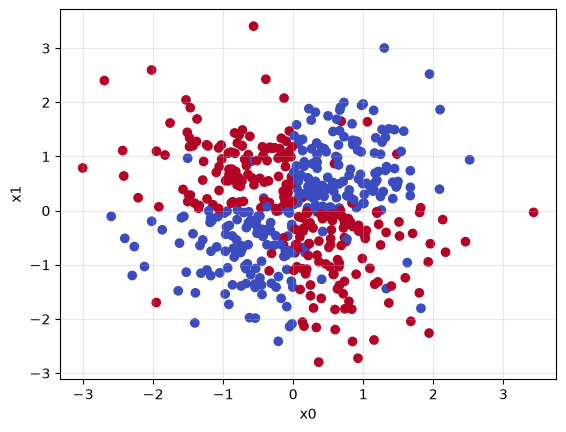

In [2]:
# This is our problem... It's basically XOR, but with continuous values (and a lot of noise!)
data = pd.read_csv("classification_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

train, val = train_test_split(train, test_size=.3, random_state=42)
X_train = train.drop(['y','split'],axis=1)
y_train = train['y']

X_val = val.drop(['y','split'],axis=1)
y_val = val['y']


X_test = test.drop(['y','split'],axis=1)
y_test = test['y']

X_train_tensor = tf.constant(X_train.values,dtype=tf.float32)
y_train_tensor = tf.constant(y_train.values,dtype=tf.float32)



plt.scatter(test["x0"], test["x1"], c=test["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.grid(True, alpha=0.3)
plt.show()




16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
lr_schedule 0.918


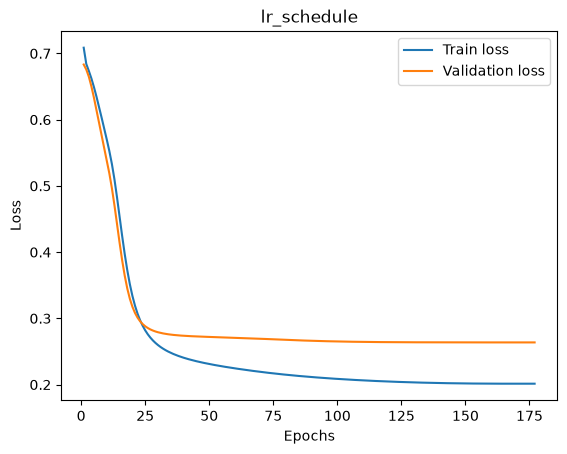

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
SGD 0.766


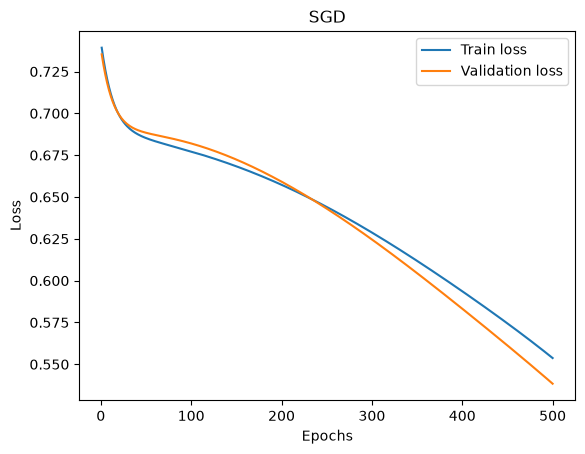

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
SGD_momentum 0.9


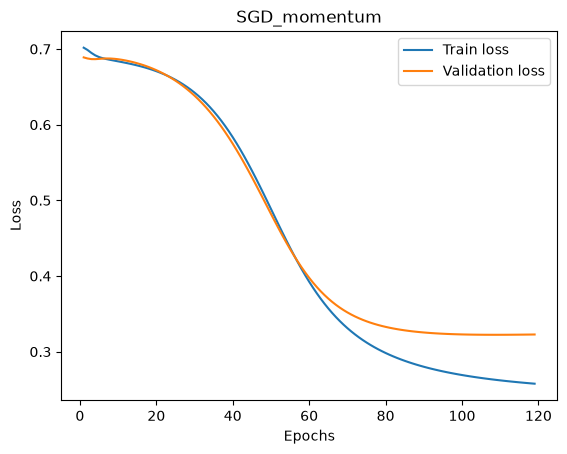

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Adam 0.9


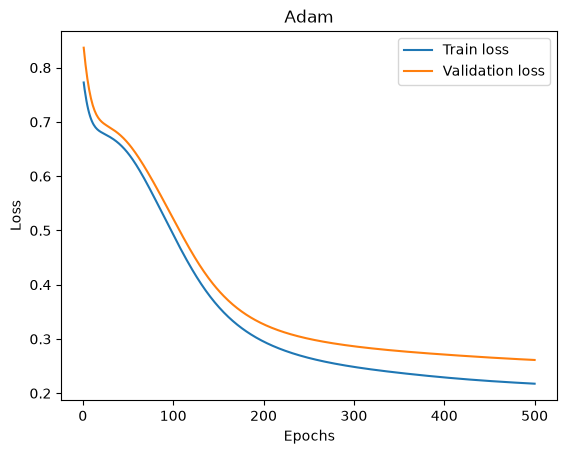

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
RMSprop 0.47


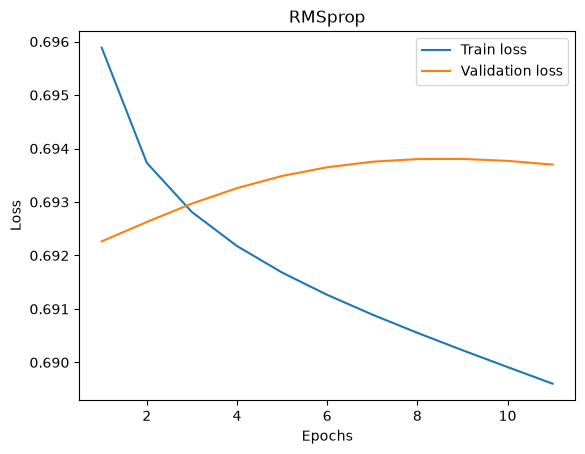

In [3]:
# ====================================
# YOUR CODE GOES HERE
# ====================================
keras.utils.set_random_seed(42)
def create_model():
    model = Sequential() 
    model.add(keras.Input(shape=(2,)))
    model.add(Dense(8, activation="tanh", name = "layer1"))
    model.add(Dense(8,activation="tanh",name="layer2"))
    model.add(Dense(1,activation="sigmoid", name="output"))
    return model 
early_stop = keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience=10,
    restore_best_weights=True
)

optimizers={
    'lr_schedule':keras.optimizers.SGD(learning_rate=keras.optimizers.schedules.CosineDecay(initial_learning_rate=.5,decay_steps=1000)),
    'SGD': keras.optimizers.SGD(learning_rate=.01),
    'SGD_momentum' :keras.optimizers.SGD(learning_rate=.01, momentum=.9),
    'Adam': keras.optimizers.Adam(learning_rate=.001),
    'RMSprop' : keras.optimizers.RMSprop(learning_rate=.001)
}
for name, optimizer in optimizers.items():
    model = create_model()
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    history = model.fit(X_train,y_train,batch_size=64,epochs=500,validation_data=(X_val, y_val),verbose=0,callbacks=[early_stop])
  
    
    y_pred = (model.predict(X_test)>=.5).astype(int).ravel()
    accuracy = np.mean(y_pred == y_test.to_numpy())
    print(name, accuracy)
    train_losses = history.history["loss"]
    val_losses = history.history["val_loss"]
    epochs = np.arange(1, len(train_losses)+1)
    plt.plot(epochs, train_losses, label="Train loss")
    plt.plot(epochs, val_losses, label="Validation loss")
    plt.title(f'{name}')
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()



Adam så bra ut, la oss fortsette med den

Prøve litt learning rates over forskjellige seeds, så ser jo da 0.003 ut til å være best

In [134]:
learning_rates = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
seeds = [1, 2, 3, 4, 5]

results = {}

for lr in learning_rates:

    scores = []

    for seed in seeds:

        keras.utils.set_random_seed(seed)

        model = create_model()

        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=lr),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        model.fit(
            X_train,
            y_train,
            batch_size=64,
            epochs=1000,
            validation_data=(X_val, y_val),
            callbacks=[early_stop],
            verbose=0
        )

        val_loss, val_acc = model.evaluate(
            X_val, y_val, verbose=0
        )

        scores.append(val_loss)

    results[lr] = (np.mean(scores), np.std(scores))

for lr, (mean_loss, std_loss) in results.items():
    print(
        f"{lr}: {mean_loss:.4f} ± {std_loss:.4f}"
    )

0.0001: 0.5042 ± 0.0328
0.0003: 0.3025 ± 0.0115
0.001: 0.2813 ± 0.0235
0.003: 0.2795 ± 0.0239
0.01: 0.2911 ± 0.0216


In [157]:
batch_sizes = [16, 32, 64, 128, len(X_train)]

for batch_size in batch_sizes:
    losses = []

    for seed in [1, 2, 3, 4, 5]:
        keras.utils.set_random_seed(seed)

        model = create_model()

        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=0.003),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        history = model.fit(
            X_train,
            y_train,
            batch_size=batch_size,
            epochs=1000,
            validation_data=(X_val, y_val),
            callbacks=[early_stop],
            verbose=0
        )

        val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)

        losses.append(val_loss)

    print(
        batch_size,
        np.mean(losses),
        np.std(losses)
    )

16 0.28629260063171386 0.02113398549975328
32 0.2812244951725006 0.02184754436446469
64 0.2794745028018951 0.023890756188270496
128 0.2841073751449585 0.02255640310121819
350 0.4404871940612793 0.20083791388749822


Tenker vi holder oss til batch size 64 i batch size jeg. Vi kan jo også sjekke om den blir bedre av et "enklere" hidden layer nettverk 

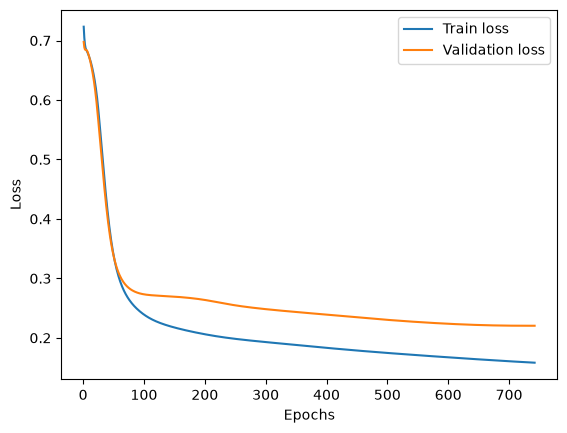

In [4]:
keras.utils.set_random_seed(42)


model = Sequential() 
model.add(keras.Input(shape=(2,)))
model.add(Dense(8, activation="tanh", name = "layer1"))
model.add(Dense(8,activation="tanh",name="layer2"))
model.add(Dense(1,activation="sigmoid", name="output"))

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.003),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=1000,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose = 0
)
train_losses = history.history["loss"]
val_losses = history.history["val_loss"]
epochs = np.arange(1, len(train_losses)+1)
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()




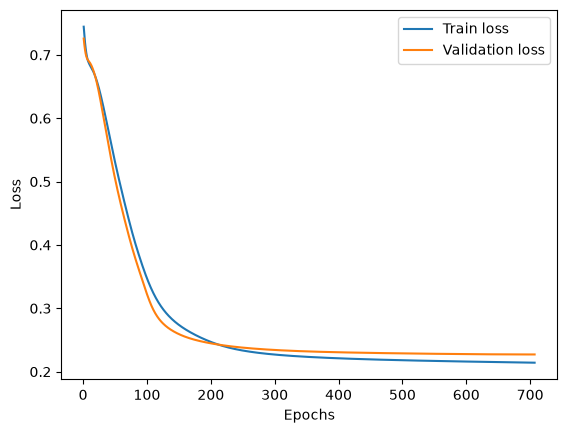

In [5]:
keras.utils.set_random_seed(42)


model = Sequential() 
model.add(keras.Input(shape=(2,)))
model.add(Dense(4, activation="tanh", name = "layer1"))
model.add(Dense(4,activation="tanh",name="layer2"))
model.add(Dense(1,activation="sigmoid", name="output"))

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.003),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=1000,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose = 0
)
train_losses = history.history["loss"]
val_losses = history.history["val_loss"]
epochs = np.arange(1, len(train_losses)+1)
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()




In [170]:
architectures = [
    (2,2),
    (2,4),
    (4,2),
    (4,4),
    (4,8),
    (8,4),
    (8,8)
]

seeds = [1,2,3,4,5]

results = {}

for architecture in architectures:

    losses = []
    accuracies = []

    for seed in seeds:

        keras.backend.clear_session()
        keras.utils.set_random_seed(seed)

        model = Sequential([
            keras.Input(shape=(2,)),
            Dense(architecture[0], activation="tanh"),
            Dense(architecture[1], activation="tanh"),
            Dense(1, activation="sigmoid")
        ])

        model.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=0.003
            ),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        model.fit(
            X_train,
            y_train,
            batch_size=64,
            epochs=1000,
            validation_data=(X_val, y_val),
            callbacks=[early_stop],
            verbose=0
        )

        val_loss, val_acc = model.evaluate(
            X_val,
            y_val,
            verbose=0
        )

        losses.append(val_loss)
        accuracies.append(val_acc)

        print(f"Done with {architecture}: seed {seed}")

    results[architecture] = {
        "loss_mean": np.mean(losses),
        "loss_std": np.std(losses),
        "acc_mean": np.mean(accuracies),
        "acc_std": np.std(accuracies)
    }

for architecture, result in results.items():
    print(
        architecture,
        f"loss: {result['loss_mean']:.4f} ± {result['loss_std']:.4f}",
        f"accuracy: {result['acc_mean']:.4f} ± {result['acc_std']:.4f}"
    )


Done with (2, 2): seed 1
Done with (2, 2): seed 2
Done with (2, 2): seed 3
Done with (2, 2): seed 4
Done with (2, 2): seed 5
Done with (2, 4): seed 1
Done with (2, 4): seed 2
Done with (2, 4): seed 3
Done with (2, 4): seed 4
Done with (2, 4): seed 5
Done with (4, 2): seed 1
Done with (4, 2): seed 2
Done with (4, 2): seed 3
Done with (4, 2): seed 4
Done with (4, 2): seed 5
Done with (4, 4): seed 1
Done with (4, 4): seed 2
Done with (4, 4): seed 3
Done with (4, 4): seed 4
Done with (4, 4): seed 5
Done with (4, 8): seed 1
Done with (4, 8): seed 2
Done with (4, 8): seed 3
Done with (4, 8): seed 4
Done with (4, 8): seed 5
Done with (8, 4): seed 1
Done with (8, 4): seed 2
Done with (8, 4): seed 3
Done with (8, 4): seed 4
Done with (8, 4): seed 5
Done with (8, 8): seed 1
Done with (8, 8): seed 2
Done with (8, 8): seed 3
Done with (8, 8): seed 4
Done with (8, 8): seed 5
(2, 2) loss: 0.5263 ± 0.1712 accuracy: 0.6920 ± 0.1289
(2, 4) loss: 0.4682 ± 0.2146 accuracy: 0.6987 ± 0.2337
(4, 2) loss: 0

8x8 modellen er best åpenbart. La oss bruke den. Den er jo egentlig grei nok nå, trenger ikke gjøre noe særlig mer.

### ❓ Visualize the network architecture for both classification and regression.


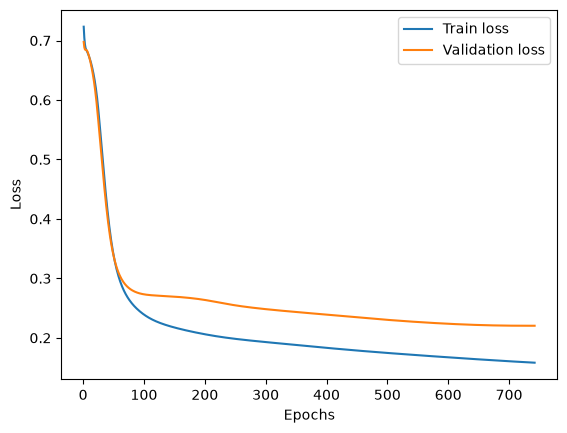

In [6]:
from keras.utils import plot_model
keras.utils.set_random_seed(42)


model_final = Sequential() 
model_final.add(keras.Input(shape=(2,)))
model_final.add(Dense(8, activation="tanh", name = "layer1"))
model_final.add(Dense(8,activation="tanh",name="layer2"))
model_final.add(Dense(1,activation="sigmoid", name="output"))

model_final.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.003),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model_final.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=1000,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose = 0
)
train_losses = history.history["loss"]
val_losses = history.history["val_loss"]
epochs = np.arange(1, len(train_losses)+1)
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()





Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 317 (1.24 KB)

 Trainable params: 105 (420.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 212 (852.00 B)

None
You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
0.912


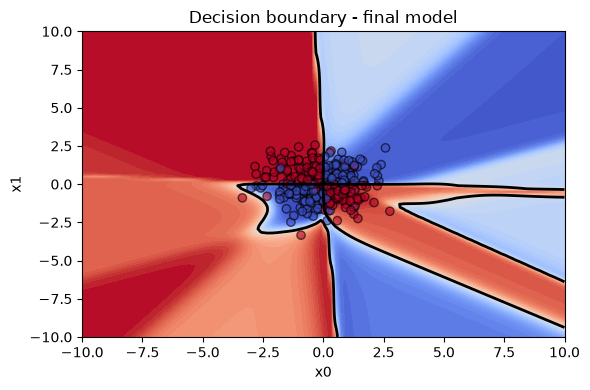

In [7]:
print(model_final.summary())
plot_model(
    model_final,
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True
)

y_pred = (model_final.predict(X_test)>=.5).astype(int).ravel()
accuracy = np.mean(y_pred == y_test.to_numpy())

print(accuracy)

fig, ax = plot_decision_boundary(
    predict=lambda X: model_final.predict(X, verbose=0),
    threshold=0.5,
    points=X_train,
    labels=y_train,
    xlim=(-10,10),
    ylim=(-10,10)
)

ax.set_title(f"Decision boundary - final model")
plt.show()


Kanskje en smule overfitting her, spesielt rundt negative x1 verdier. Kan bli problematisk for større verdier. Over ser man også arkitekturen. 

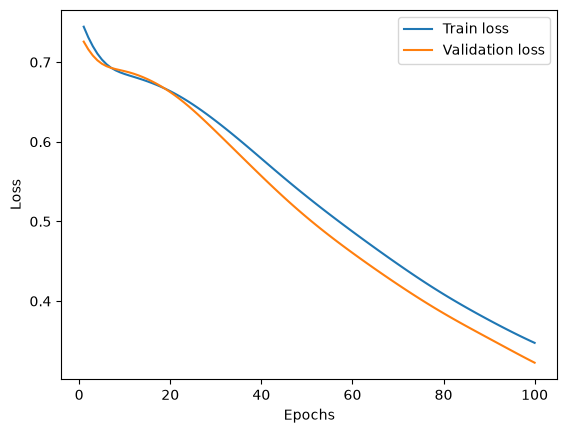

In [9]:
from keras.utils import plot_model
from keras import regularizers
keras.utils.set_random_seed(42)


model_final = Sequential() 
model_final.add(keras.Input(shape=(2,)))
model_final.add(Dense(4, activation="tanh"))
model_final.add(Dense(4,activation="tanh",name="layer2"))
model_final.add(Dense(1,activation="sigmoid", name="output"))

model_final.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.003),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

history = model_final.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=100,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose = 0
    
)
train_losses = history.history["loss"]
val_losses = history.history["val_loss"]
epochs = np.arange(1, len(train_losses)+1)
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()





16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
0.862


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113 (456.00 B)

 Trainable params: 37 (148.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 76 (308.00 B)

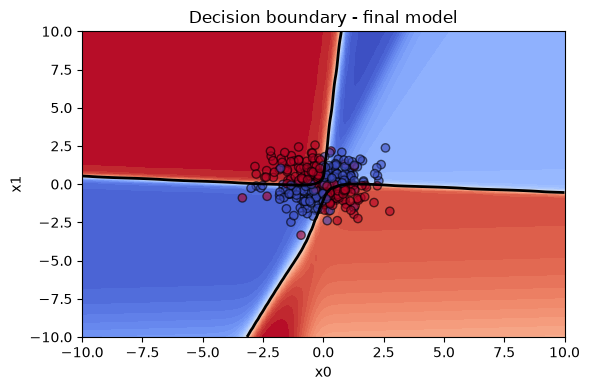

In [10]:
y_pred = (model_final.predict(X_test)>=.5).astype(int).ravel()
accuracy = np.mean(y_pred == y_test.to_numpy())

print(accuracy)
model_final.summary()
fig, ax = plot_decision_boundary(
    predict=lambda X: model_final.predict(X, verbose=0),
    threshold=0.5,
    points=X_train,
    labels=y_train,
    xlim=(-10,10),
    ylim=(-10,10)
)

ax.set_title(f"Decision boundary - final model")
plt.show()

### ❓ Plot the classification decision boundary. Would the model generalize to larger feature values? 
The the positive x1 direction it seems to generalize good. I tried to simplify the model a bit using 2x4 layers instead in the last bit of code. It seems to generalize a bit better for larger values, but at the cost of accuracy. Could be something to look into.  

## Regression


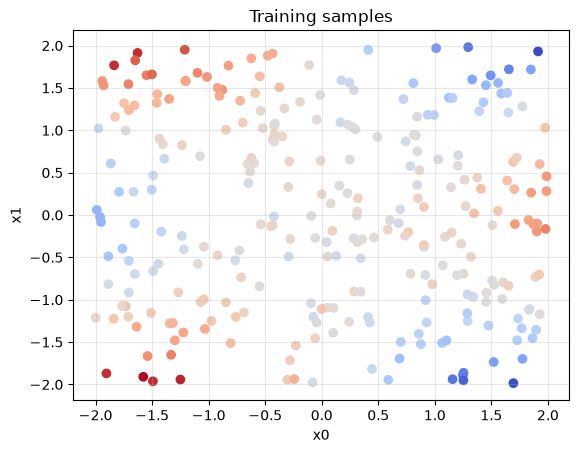

In [11]:
# We have a new dataset now. This time, the target is continuous.
# Test rows have no y. For a validation split, hold out part of train.

import itertools 
import numpy as np 
data = pd.read_csv("regression_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]
train, val = train_test_split(train, test_size=.3, random_state=42)
X_train = train.drop(['y','split'],axis=1)
y_train = train['y']

X_val = val.drop(['y','split'],axis=1)
y_val = val['y']
plt.scatter(train["x0"], train["x1"], c=train["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.title("Training samples")
plt.grid(True, alpha=0.3)
plt.show()

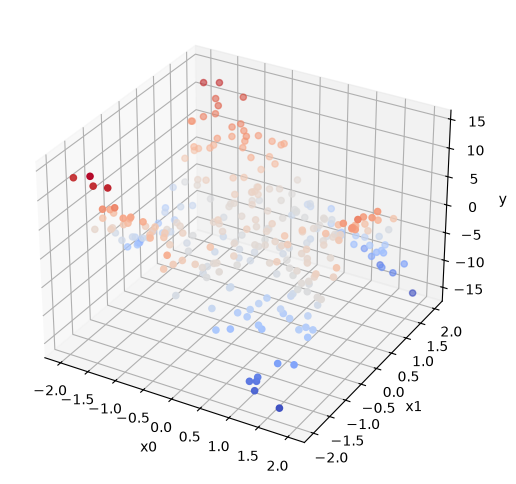

In [12]:
# Hmmm, maybe 3d is better
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(train["x0"], train["x1"], train["y"], c=train["y"], cmap="coolwarm")
ax.set_xlabel("x0")
ax.set_ylabel("x1")
ax.set_zlabel("y")
plt.show()

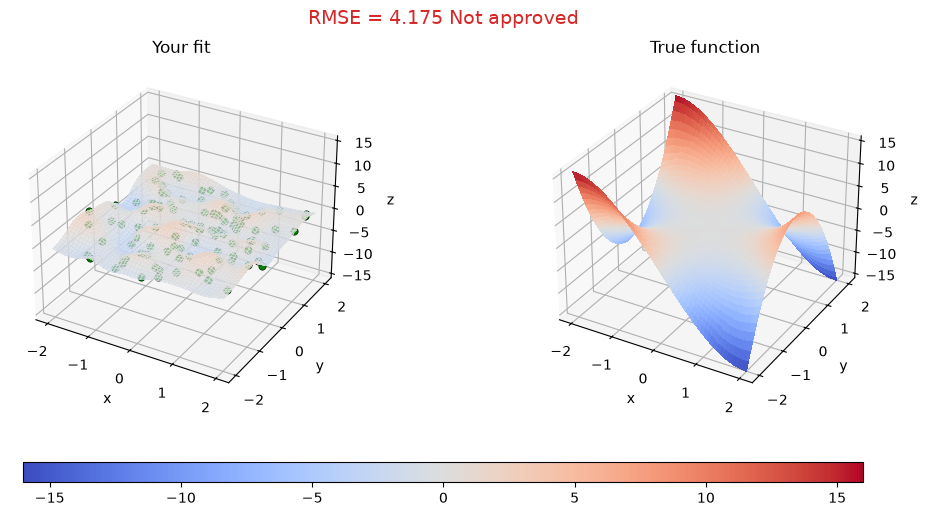

In [13]:
# plot_complex_fit compares your predictions to the true surface and prints RMSE
# plot_complex_fit has no noise, so expect a lower RMSE here
# The test rows have no y, so this is how you score them.
test_xy = test[["x0", "x1"]].values
y_pred_demo = np.random.randn(len(test))

plot_complex_fit(test_xy, y_pred_demo)
plt.show()

# Random predictions fail the 0.25 RMSE threshold.

In [15]:

import numpy as np
import pandas as pd
import keras
import time

def create_model(architecture, activation):
    model = keras.Sequential([
        keras.Input(shape=(X_train.shape[1],)),
        *[
            keras.layers.Dense(n, activation=activation)
            for n in architecture
        ],
        keras.layers.Dense(1)
    ])
    return model

X_val_np = np.asarray(X_val)
true_y = complex_function(X_val_np[:, 0], X_val_np[:, 1])


def train_and_evaluate(config, seed=42, epochs=400, patience=25):

    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    model = create_model(
        config["architecture"],
        config["activation"]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=config["lr"]
        ),
        loss="mse"
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=patience,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        batch_size=config["batch_size"],
        epochs=epochs,
        callbacks=[early_stop],
        verbose=0
    )

    pred = model.predict(X_val, verbose=0).ravel()

    true_rmse = np.sqrt(np.mean((pred - true_y)**2))
    val_rmse = np.sqrt(
        np.mean((pred - np.asarray(y_val).ravel())**2)
    )

    return true_rmse, val_rmse, len(history.history["loss"])


# Startkonfigurasjon
best_config = {
    "architecture": (64, 64),
    "activation": "relu",
    "lr": 0.001,
    "batch_size": 64
}

search_space = [
    ("lr", [0.001, 0.003, 0.01]),
    ("activation", ["relu", "tanh", "gelu"]),
    ("architecture", [(32,32), (64,64), (128,128)]),
    ("batch_size", [32, 64])
]

results = []
start = time.perf_counter()

for parameter, values in search_space:

    print(f"\n--- Optimizing {parameter} ---")
    stage_results = []

    for value in values:

        config = best_config.copy()
        config[parameter] = value

        rmse, val_rmse, n_epochs = train_and_evaluate(config)

        result = {
            **config,
            "true_rmse": rmse,
            "val_rmse": val_rmse,
            "epochs": n_epochs
        }

        results.append(result)
        stage_results.append(result)

        print(
            f"{parameter}={value}: "
            f"RMSE={rmse:.4f}, "
            f"epochs={n_epochs}"
        )

    # Velg beste verdi for denne hyperparameteren
    best = min(stage_results, key=lambda x: x["true_rmse"])
    best_config[parameter] = best[parameter]

    print(f"BEST {parameter}: {best[parameter]}")
    print(f"RMSE: {best['true_rmse']:.4f}")

print("\nFINAL CONFIGURATION:")
print(best_config)

print(f"\nTime: {(time.perf_counter()-start)/60:.1f} min")

results_df = pd.DataFrame(results)
display(results_df)



--- Optimizing lr ---

lr=0.001: RMSE=0.5275, epochs=400
lr=0.003: RMSE=0.5402, epochs=160
lr=0.01: RMSE=0.5225, epochs=77
BEST lr: 0.01
RMSE: 0.5225

--- Optimizing activation ---
activation=relu: RMSE=0.5225, epochs=77
activation=tanh: RMSE=0.5697, epochs=147
activation=gelu: RMSE=0.3128, epochs=72
BEST activation: gelu
RMSE: 0.3128

--- Optimizing architecture ---
architecture=(32, 32): RMSE=0.3779, epochs=92
architecture=(64, 64): RMSE=0.3128, epochs=72
architecture=(128, 128): RMSE=0.3516, epochs=76
BEST architecture: (64, 64)
RMSE: 0.3128

--- Optimizing batch_size ---
batch_size=32: RMSE=0.3264, epochs=70
batch_size=64: RMSE=0.3128, epochs=72
BEST batch_size: 64
RMSE: 0.3128

FINAL CONFIGURATION:
{'architecture': (64, 64), 'activation': 'gelu', 'lr': 0.01, 'batch_size': 64}

Time: 2.4 min


,architecture,activation,lr,batch_size,true_rmse,val_rmse,epochs
0,"(64, 64)",relu,0.001,64,0.527545,1.209583,400
1,"(64, 64)",relu,0.003,64,0.540226,1.215160,160
2,"(64, 64)",relu,0.010,64,0.522520,1.196486,77
3,"(64, 64)",relu,0.010,64,0.522520,1.196486,77
4,"(64, 64)",tanh,0.010,64,0.569714,1.193294,147
5,"(64, 64)",gelu,0.010,64,0.312836,1.101139,72
6,"(32, 32)",gelu,0.010,64,0.377869,1.112184,92
7,"(64, 64)",gelu,0.010,64,0.312836,1.101139,72
8,"(128, 128)",gelu,0.010,64,0.351607,1.113664,76
9,"(64, 64)",gelu,0.010,32,0.326386,1.113929,70


In [16]:
seeds = [1, 2, 3]
rmses = []

for seed in seeds:
    rmse, val_rmse, epochs = train_and_evaluate(
        best_config,
        seed=seed,
        epochs=1000,
        patience=50
    )

    rmses.append(rmse)
    print(f"Seed {seed}: RMSE = {rmse:.4f}")

print(
    f"\nMean RMSE: {np.mean(rmses):.4f}"
    f" ± {np.std(rmses):.4f}"
)

Seed 1: RMSE = 0.3276
Seed 2: RMSE = 0.3226
Seed 3: RMSE = 0.3067

Mean RMSE: 0.3190 ± 0.0089


deilig, må dra den hakket lengre ned bare. Sweepe litt rundt et par verdier og standarisering gjør kanskje susen :D


In [17]:
from sklearn.preprocessing import StandardScaler
from keras.models import Sequential
from keras.layers import Dense

x_scaler = StandardScaler()

X_train_s = x_scaler.fit_transform(X_train).astype("float32")
X_val_s = x_scaler.transform(X_val).astype("float32")


# Standardiser y
y_scaler = StandardScaler()
y_train_s = y_scaler.fit_transform(
    np.asarray(y_train).reshape(-1, 1)
).astype("float32")

y_val_s = y_scaler.transform(
    np.asarray(y_val).reshape(-1, 1)
).astype("float32")

# Fasit på valideringspunktene i original skala
X_val_np = np.asarray(X_val)

true_y = complex_function(
    X_val_np[:, 0],
    X_val_np[:, 1]
)

architectures = [
    (64, 64),
    (128, 64),
    (128, 128)
]

learning_rates = [
    3e-4,
    1e-3,
    3e-3
]

seeds = [1, 2]

results = []



def create_model_gelu(architecture):
    model = Sequential()
    model.add(keras.Input(shape=(X_train_s.shape[1],)))

    for n in architecture:
        model.add(Dense(n, activation="gelu"))

    model.add(Dense(1))
    return model


def train_model_new(architecture, lr, seed):

    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    model = create_model_gelu(architecture)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="mse"
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=40,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_s,
        y_train_s,
        validation_data=(X_val_s, y_val_s),
        epochs=700,
        batch_size=64,
        callbacks=[early_stop],
        verbose=0
    )

   
    pred_s = model.predict(X_val_s, verbose=0)

    
    pred = y_scaler.inverse_transform(pred_s).ravel()

    
    true_rmse = np.sqrt(np.mean((pred - true_y)**2))

    
    val_rmse = np.sqrt(
        np.mean((pred - np.asarray(y_val).ravel())**2)
    )

    return model, true_rmse, val_rmse, len(history.history["loss"]), history



In [ ]:

combinations = list(itertools.product(
    architectures, learning_rates, seeds
))

total = len(combinations)
start = time.perf_counter()

for i, (architecture, lr, seed) in enumerate(combinations, 1):

    model, true_rmse, val_rmse, epochs,history = train_model_new(
        architecture, lr, seed
    )

    results.append({
        "architecture": architecture,
        "lr": lr,
        "seed": seed,
        "true_rmse": true_rmse,
        "val_rmse": val_rmse,
        "epochs": epochs
    })

    elapsed = time.perf_counter() - start
    eta = elapsed / i * (total - i)

    print(
        f"[{i}/{total}] "
        f"arch={architecture}, lr={lr}, seed={seed} | "
        f"RMSE={true_rmse:.4f} | "
        f"epochs={epochs} | "
        f"ETA={eta/60:.1f} min",
        flush=True
    )

results_df = pd.DataFrame(results)

summary = (
    results_df
    .groupby(["architecture", "lr"])
    .agg(
        mean_rmse=("true_rmse", "mean"),
        std_rmse=("true_rmse", "std"),
        mean_val_rmse=("val_rmse", "mean"),
        mean_epochs=("epochs", "mean")
    )
    .reset_index()
    .sort_values("mean_rmse")
)

display(summary)


best = summary.iloc[0]

best_arch = tuple(best["architecture"])
best_lr = float(best["lr"])

print("Best architecture:", best_arch)
print("Best learning rate:", best_lr)
print("Mean RMSE:", best["mean_rmse"])


[1/18] arch=(64, 64), lr=0.0003, seed=1 | RMSE=0.3998 | epochs=700 | ETA=19.7 min
[2/18] arch=(64, 64), lr=0.0003, seed=2 | RMSE=0.3969 | epochs=700 | ETA=18.2 min
[3/18] arch=(64, 64), lr=0.001, seed=1 | RMSE=0.2317 | epochs=700 | ETA=17.2 min
[4/18] arch=(64, 64), lr=0.001, seed=2 | RMSE=0.2699 | epochs=700 | ETA=16.1 min
[5/18] arch=(64, 64), lr=0.003, seed=1 | RMSE=0.2549 | epochs=572 | ETA=14.5 min
[6/18] arch=(64, 64), lr=0.003, seed=2 | RMSE=0.2430 | epochs=620 | ETA=13.2 min
[7/18] arch=(128, 64), lr=0.0003, seed=1 | RMSE=0.3647 | epochs=700 | ETA=12.1 min
[8/18] arch=(128, 64), lr=0.0003, seed=2 | RMSE=0.3675 | epochs=700 | ETA=11.0 min
[9/18] arch=(128, 64), lr=0.001, seed=1 | RMSE=0.2385 | epochs=666 | ETA=9.9 min
[10/18] arch=(128, 64), lr=0.001, seed=2 | RMSE=0.2486 | epochs=642 | ETA=8.8 min
[11/18] arch=(128, 64), lr=0.003, seed=1 | RMSE=0.2786 | epochs=380 | ETA=7.4 min
[12/18] arch=(128, 64), lr=0.003, seed=2 | RMSE=0.2935 | epochs=246 | ETA=5.9 min
[13/18] arch=(128, 

,architecture,lr,mean_rmse,std_rmse,mean_val_rmse,mean_epochs
7,"(128, 128)",0.0010,0.210475,0.012308,1.088048,700.0
4,"(128, 64)",0.0010,0.243554,0.007119,1.097369,654.0
2,"(64, 64)",0.0030,0.248948,0.008433,1.089090,596.0
1,"(64, 64)",0.0010,0.250818,0.027040,1.100562,700.0
8,"(128, 128)",0.0030,0.271441,0.012230,1.102802,455.0
5,"(128, 64)",0.0030,0.286053,0.010479,1.113325,313.0
6,"(128, 128)",0.0003,0.303228,0.002070,1.109821,700.0
3,"(128, 64)",0.0003,0.366104,0.001919,1.132291,700.0
0,"(64, 64)",0.0003,0.398349,0.001989,1.150646,700.0


Best architecture: (128, 128)
Best learning rate: 0.001
Mean RMSE: 0.21047528621180006


ValueError: too many values to unpack (expected 4, got 5)

Final RMSE: 0.2243


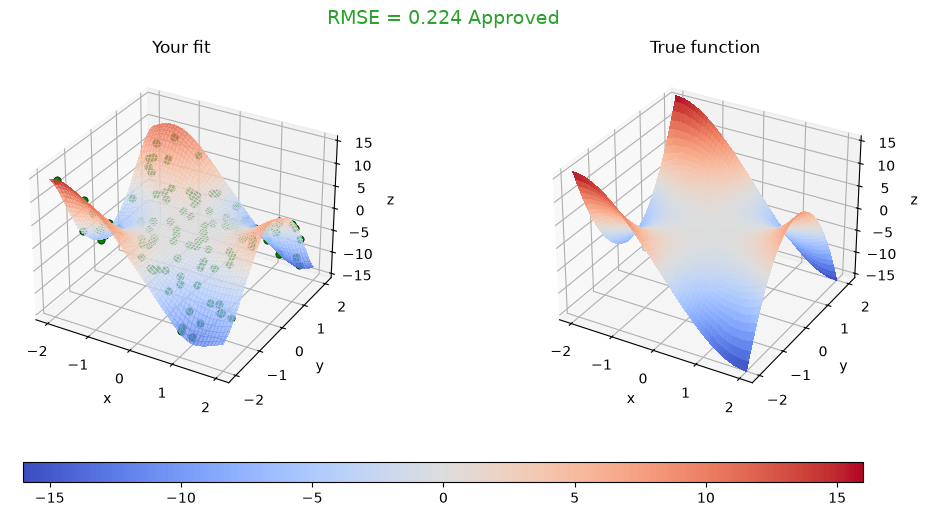

In [20]:

best_model, true_rmse, val_rmse, epochs,history = train_model_new(
    best_arch,
    best_lr,
    seed=42
)


y_pred_s = best_model.predict(X_val_s, verbose=0)

y_pred = y_scaler.inverse_transform(y_pred_s).ravel()


fig, axes, rmse = plot_complex_fit(
    X_val_np,
    y_pred
)

print(f"Final RMSE: {rmse:.4f}")

c:\Users\fredr\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Test RMSE: 0.2465


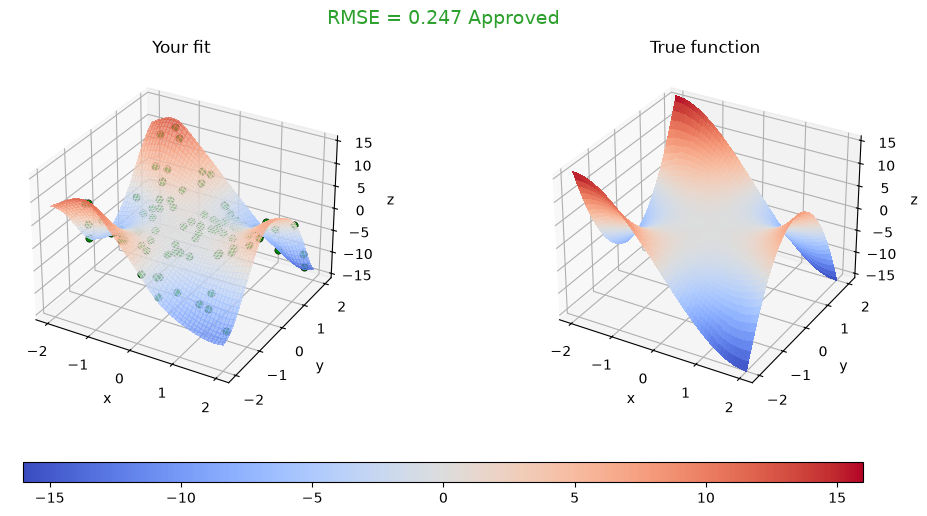

In [21]:
test_xy = test[["x0", "x1"]].values
pred_s = best_model.predict(x_scaler.transform(test_xy).astype("float32"), verbose=0)
pred = y_scaler.inverse_transform(pred_s).ravel()
fig, axes, rmse = plot_complex_fit(test_xy, pred)
print(f"Test RMSE: {rmse:.4f}")

Fantastisk, (128,128), .001 lr putter oss innafor kravene på valideringen og på testset. Jeg kunne nok dratt den lengre ned, burde for eksempel implementert en k fold cval på den. jeg oppdaterer train new litt.

In [24]:
def train_model_new(
    architecture, lr, seed,
    X_train_s, y_train_s,
    X_val_s, y_val_s,
    X_eval_s, y_eval, y_scaler
):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    model = create_model_gelu(architecture)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="mse"
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=40,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_s,
        y_train_s,
        validation_data=(X_val_s, y_val_s),
        epochs=700,
        batch_size=64,
        callbacks=[early_stop],
        verbose=0
    )

    # Evaluer på den eksterne folden
    pred_s = model.predict(X_eval_s, verbose=0)
    pred = y_scaler.inverse_transform(pred_s).ravel()

    rmse = np.sqrt(
        np.mean((pred - np.asarray(y_eval).ravel())**2)
    )

    return model, rmse, len(history.history["loss"]), history

In [23]:
best = summary.iloc[0]
print(best)

best_architecture = tuple(best["architecture"])
best_lr = float(best["lr"])

FINAL_SEED = 42

final_model, rmse, val_rmse, epochs,history = train_model_new(
    architecture=best_architecture,
    lr=best_lr,
    seed=FINAL_SEED
)

print(f"Final RMSE: {rmse:.4f}")

architecture     (128, 128)
lr                    0.001
mean_rmse          0.210475
std_rmse           0.012308
mean_val_rmse      1.088048
mean_epochs           700.0
Name: 7, dtype: object
Final RMSE: 0.2243


In [ ]:
final_model.save("regression_gelu.keras")
import joblib

joblib.dump(x_scaler, "x_scaler.pkl")
joblib.dump(y_scaler, "y_scaler.pkl")

''' 
Hvis jeg senere skal laste inn modellen gjør jeg da 
model = keras.models.load_model("regression_gelu.keras")

x_scaler = joblib.load("x_scaler.pkl")
y_scaler = joblib.load("y_scaler.pkl")

X_new_scaled = x_scaler.transform(X_new)

pred_scaled = model.predict(X_new_scaled)

pred = y_scaler.inverse_transform(pred_scaled)
'''

['y_scaler.pkl']

### ❓ Plot train and held-out loss vs. epoch. What do these curves tell you? Are the final values a good way to judge the model?


In [43]:
model, true_rmse, val_rmse, n_epochs, history = train_model_new(
    architecture=(128, 128),
    lr=0.001,
    seed=42
)

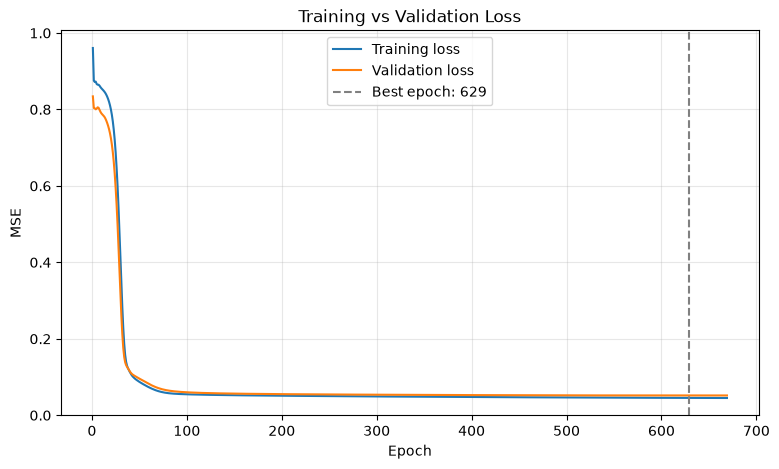

Best epoch: 629
Minimum validation loss: 0.05182
Final validation loss: 0.05185


In [44]:
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = np.arange(1, len(train_loss) + 1)
best_epoch = np.argmin(val_loss) + 1

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_loss, label="Training loss")
plt.plot(epochs, val_loss, label="Validation loss")

plt.axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Best epoch: {best_epoch}")
print(f"Minimum validation loss: {min(val_loss):.5f}")
print(f"Final validation loss: {val_loss[-1]:.5f}")

Here you have val loss vs training loss. As you can see its good convergence which indicates good fitting. They go together and flat out together at a pretty low level. If it was overfitted the val loss would increase, and if it was underfitting it would go that low.
However, the final values are probably not a good way to judge the model alone. If you just look at the last value you could be seeing a very low training loss which looks like a success, but the best epoch might be hundreds ago. But therefore we have early stop with restore best weights. Therefore we dont use the final value, but the best one. this also stops overfitting. 

### ❓ Which optimization techniques did you try? What worked and what did not?
I experimented with several optimization techinques to improve both neural networks. 
For classification, Adam performed well with a learning rate of .003 giving the lowest average validation loss among the tested values. However its performance was very similar to that of .001. Using tanh activation in the hidden layers allowed the network to leaern the XOR like decision boundary effectively, achiecing up to 94% validation accuracy. 

For regression, the initial ReLU based network captured the general shape of the underlying function, but struggled to reach the required accuracy. Switching to GELU activation combined with standardization of features and targets allowed me to push the RMSE within the required values. 

Early stopping was used throughout every test to limit unnecessary training and to restore weights corresponding to lowest val loss. I also evaluated loss accross multiple seed to reduce the randomness.

Overall I found that carefully selecting learning rate and activation function was particulary important, and model complexity wasnt necessarily needed to improce the model. 


### ❓ How did you ensure reproducibility?
I used fixed random seeds for model initialization and data splitting. This allowed me to repeat experiments under consistent conditions. 

I evaluated different hyperparameter configs across multiple seeds, comparing the mean and standard deviation of validation performance. This reduced the risk of selecting a model based on a lucky seed. 

I also kept the training and val sets consistent across hyperparameter tuning, and I used the same evaluation metrcis across experiments. 

# 🤖 Problem 2: Unsupervised Learning

### ❗️ The problem

1. Identify the number of clusters in the dataset.
2. Assign a cluster label to every row and validate on [Kaggle](https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86) until you reach at least **99%** clustering accuracy.
3. Visualize the clusters in 2D, and identify what each cluster is.
4. Some rows do not belong with the others. Find those rows and show what they are.

### 💡 Hints

1. **Large Dataset**: The data set **unsupervised_data.csv** is huge! There are many features, dimensionality reduction can help.
2. **Unsupervised Learning**: No target labels are provided, patterns must come from the features alone.
3. **Data Obfuscation**: The data has a structured format. Try to find the meaning and correct ordering of the features.

### 📚 Resources

- [Clustering in scikit-learn](https://scikit-learn.org/stable/modules/clustering.html) (KMeans, DBSCAN, …)
- [Manifold learning](https://scikit-learn.org/stable/modules/manifold.html) (PCA, t-SNE, …)
- Feel free to use any other methods you find in the scikit-learn documentation!
- Kaggle competition (50 submissions per day)

### 📋 Formal requirements

1. Identify the number of clusters in the dataset.
2. Reach at least **99%** clustering accuracy on Kaggle.
3. Visualize the clusters in 2D.
4. Identify what each cluster corresponds to.
5. Some rows do not belong here, perform anomaly detection and find those samples.
6. **Discussion**
   - Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.
   - Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.
   - What is the hidden modality? How does this impact dimensionality reduction and clustering?
   - List the facilities in Trondheim and how you identified them.
   - How did you detect the rows that do not belong, and what were they?

## 🏆 Kaggle

Kaggle is a popular platform for machine learning competitions. It allows hosts to share datasets while keeping the labels hidden from the participants. The clustering labels are not available locally. Use **Kaggle** to check your cluster assignments.

- Invitation: https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86
- Upload a CSV with columns `ID` and `cluster` (integer cluster ids) to check your score.
- Also include the final **submission.csv** in your Canvas delivery, together with the notebook.


In [54]:
# Why did we skip the first row? Maybe it's useful metadata for later...
data = pd.read_csv("unsupervised_data.csv", skiprows=1, header=None)
data = data.reset_index(names="ID")
data

C:\Users\fredr\AppData\Local\Temp\ipykernel_5592\3436741196.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data = data.reset_index(names="ID")


,ID,0,1,2,3,4,5,6,7,8,...,16374,16375,16376,16377,16378,16379,16380,16381,16382,16383
0,0,0.314365,0.646305,0.323849,0.238492,0.655790,0.646305,0.646305,0.409205,0.646305,...,0.646305,0.646305,0.655790,0.238492,0.646305,0.674758,0.646305,0.238492,0.655790,0.646305
1,1,0.587628,0.494976,0.559832,-0.246237,0.513506,0.550567,0.522772,0.596893,0.606158,...,0.587628,0.550567,0.587628,0.587628,0.550567,0.587628,0.550567,0.596893,0.494976,0.587628
2,2,0.590203,0.367673,0.367673,0.367673,0.367673,0.590203,0.367673,0.590203,0.590203,...,0.590203,0.367673,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.476556
3,3,0.589296,0.589296,0.579825,0.551415,0.579825,0.579825,0.608236,0.579825,0.646118,...,0.532474,0.523003,0.589296,0.589296,0.551415,0.134721,0.475652,0.589296,0.570355,0.551415
4,4,0.660095,0.470676,0.190366,0.672806,0.470761,0.672766,0.672652,0.666151,0.672987,...,0.432001,0.672222,0.190568,0.217329,0.633684,0.673294,0.587914,0.671023,0.207578,0.470765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,3995,0.340739,0.340739,0.340739,0.681823,0.340739,0.340739,0.340739,0.672083,0.340739,...,0.340739,0.662355,0.340739,0.759779,0.331011,0.759779,0.340739,0.691563,0.340734,0.720789
3996,3996,0.384257,0.384257,0.675221,0.384257,0.384257,0.675221,0.384257,0.675221,0.675221,...,0.675221,0.384257,0.675221,0.675221,0.675221,0.384257,0.384257,0.384257,0.675221,0.675221
3997,3997,0.641837,0.651135,0.251329,0.251329,0.651135,0.651135,0.251329,0.651135,0.651135,...,0.251329,0.251329,0.651135,0.251329,0.409392,0.604646,0.651135,0.651135,0.660433,0.251329
3998,3998,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,-0.212897,0.555533,...,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533


In [55]:
# Probably too many columns for naive clustering on raw pixels
data.info(max_cols=5)

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Columns: 16385 entries, ID to 16383
dtypes: float64(16384), int64(1)
memory usage: 500.0 MB


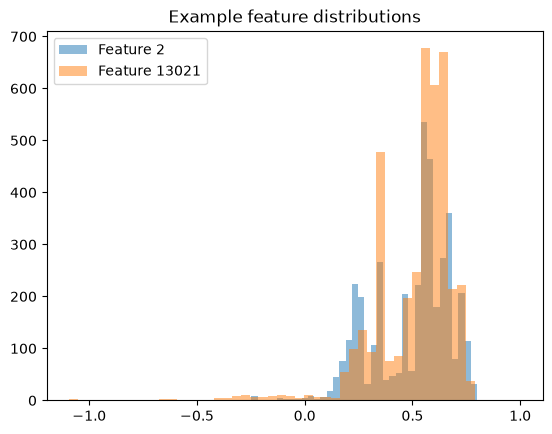

In [56]:
features = data.drop(columns="ID")
plt.hist(features.iloc[:, 2], bins=50, alpha=0.5, label="Feature 2")
plt.hist(features.iloc[:, 13021], bins=50, alpha=0.5, label="Feature 13021")
plt.legend()
plt.title("Example feature distributions")
plt.show()

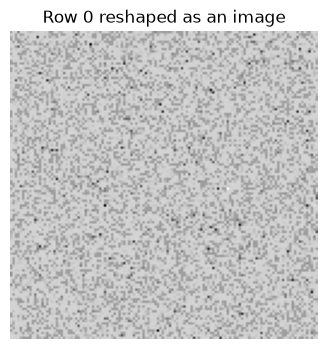

In [57]:
# 16384 = 128 × 128. Coincidence? This may be a flattened grayscale image...
row = data.iloc[0, 1:].astype(float).to_numpy()
image = row.reshape(128, 128).T
image = (image - image.min()) / (image.max() - image.min() + 1e-8)

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Row 0 reshaped as an image")
plt.axis("off")
plt.show()

# If it really is an image, then pixels look scrambled.
# The true order may be encoded elsewhere. Maybe the dropped row contained important information?

In [58]:
# Kaggle submission format. The cluster ids here are just placeholders and do not hint at k.
sample_submission = pd.read_csv("sample_submission.csv")
sample_submission.head()

,ID,cluster
0,0,2
1,1,6
2,2,3
3,3,3
4,4,8


In [13]:
# ====================================
# YOUR CODE GOES HERE
# ====================================

In [62]:
#imports 
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA 
from sklearn.manifold import TSNE

X = data.drop(columns=["ID"]).to_numpy(dtype=np.float32)

print("Shape:", X.shape)
print("Pixel range:", X.min(), X.max())

# Hvis pikslene ligger mellom 0 og 255:
if X.min() >= 0 and X.max() > 1 and X.max() <= 255:
    X = X / 255.0

Shape: (4000, 16384)
Pixel range: -4.540734 1.0


16384 ['col_9858' 'col_2932' 'col_12843' 'col_5156' 'col_2677' 'col_9520'
 'col_291' 'col_14843' 'col_10287' 'col_196'] 16384 col_0 col_9999


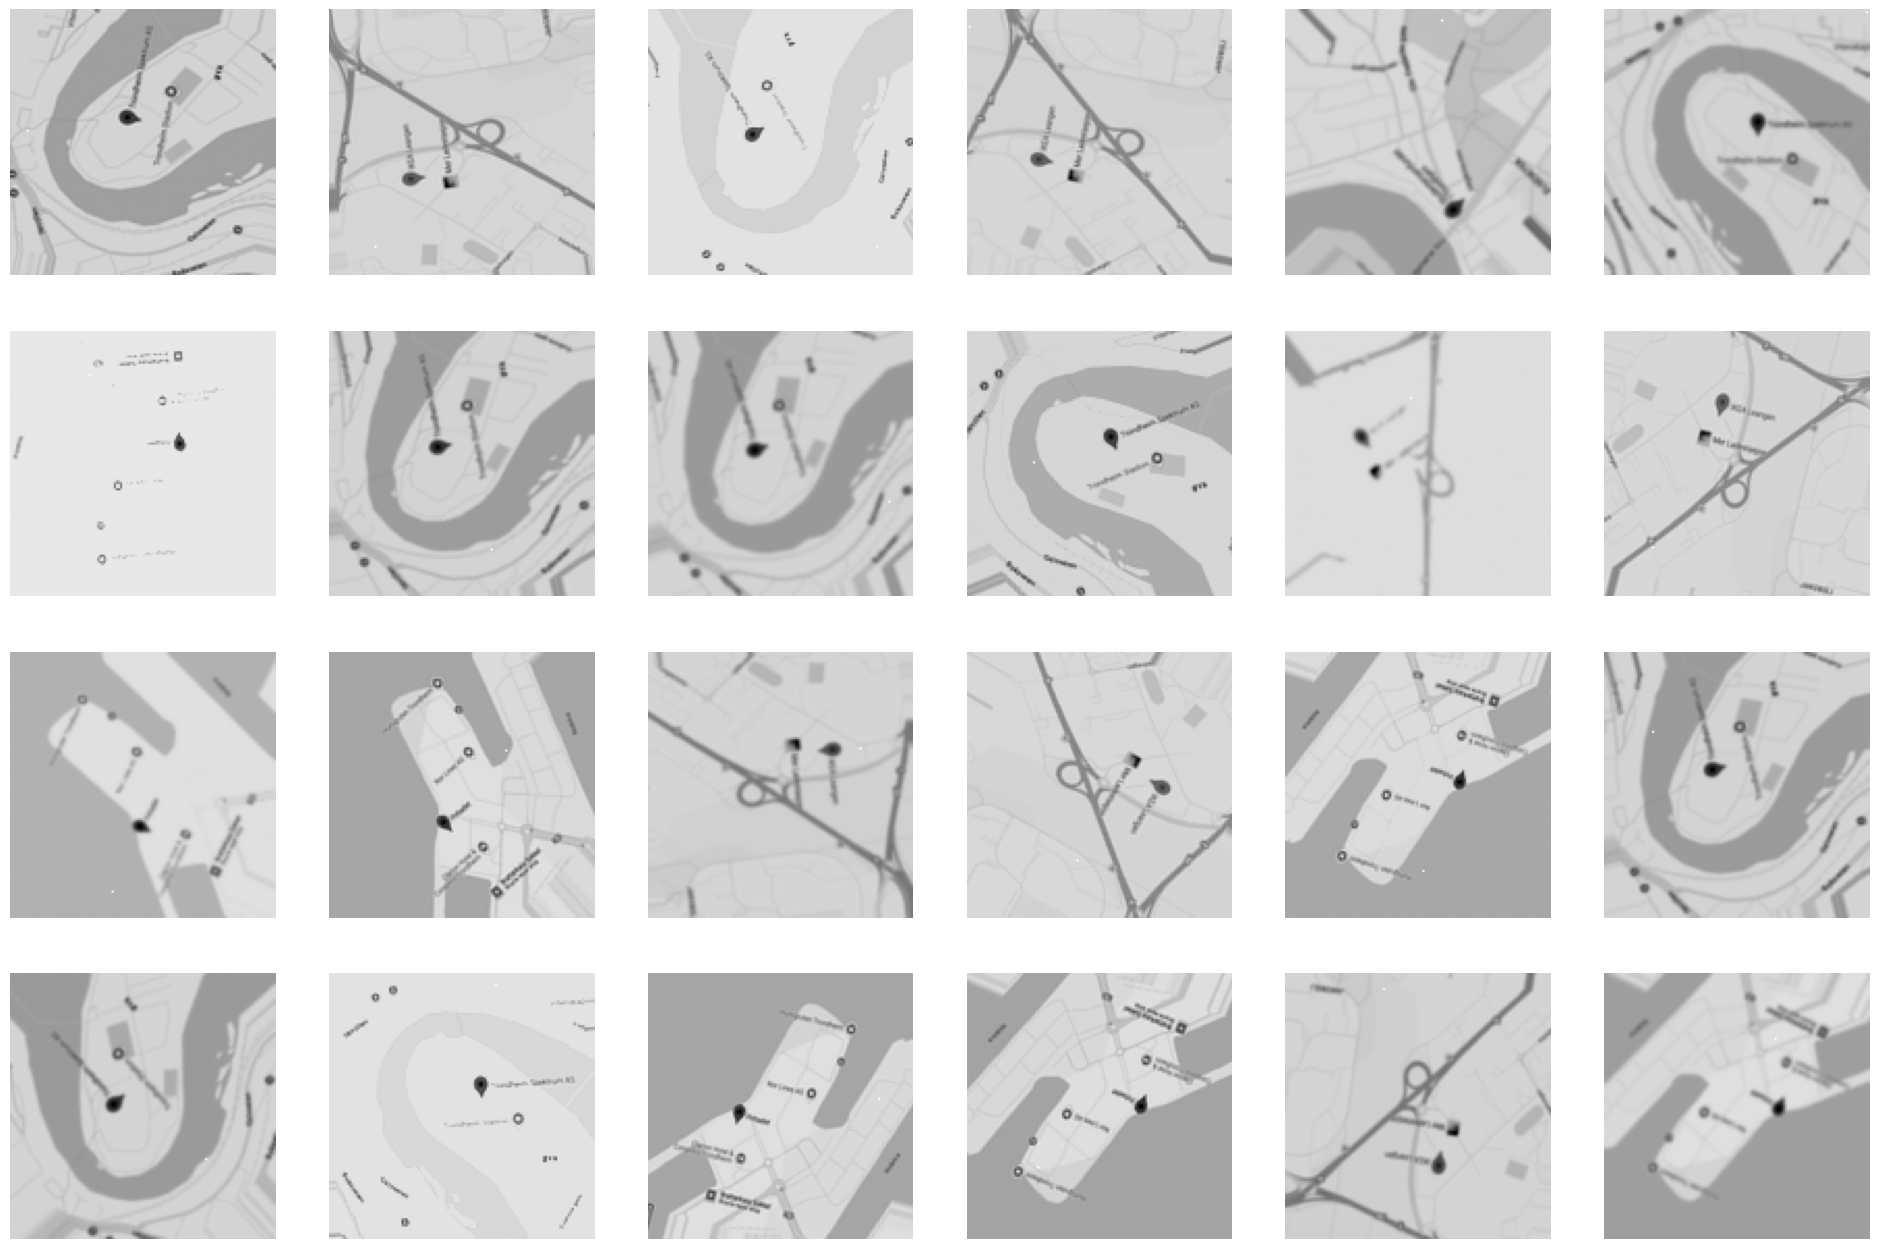

In [129]:
meta = pd.read_csv("unsupervised_data.csv", header=None, nrows=1).iloc[0].to_numpy()
print(len(meta), meta[:10], len(np.unique(meta)), meta.min(), meta.max())

pos = np.array([int(name.split("_")[1]) for name in meta])   # sann posisjon per kolonne

X = data.drop(columns="ID").to_numpy()                       # (4000, 16384), blandet
X_ordered = np.empty_like(X)
X_ordered[:, pos] = X                                        # kolonne j hører hjemme på plass pos[j]
# tilsvarende: X_ordered = X[:, np.argsort(pos)]

imgs = X_ordered.reshape(-1, 128, 128)
fig, axes = plt.subplots(4, 6, figsize=(24, 16))
for ax, im in zip(axes.ravel(), imgs[:24]):
    ax.imshow(im, cmap="gray"); ax.axis("off")
plt.show()


In [101]:
imgs_flat = X_ordered.reshape(len(X_ordered), -1)
mu = imgs_flat.mean(axis=1, keepdims=True)
sd = imgs_flat.std(axis=1, keepdims=True)
X_norm = (imgs_flat - mu) / (sd + 1e-8)


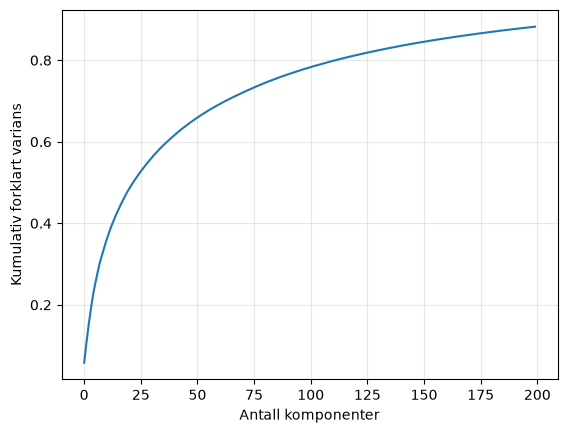

90% varians: 201 komponenter


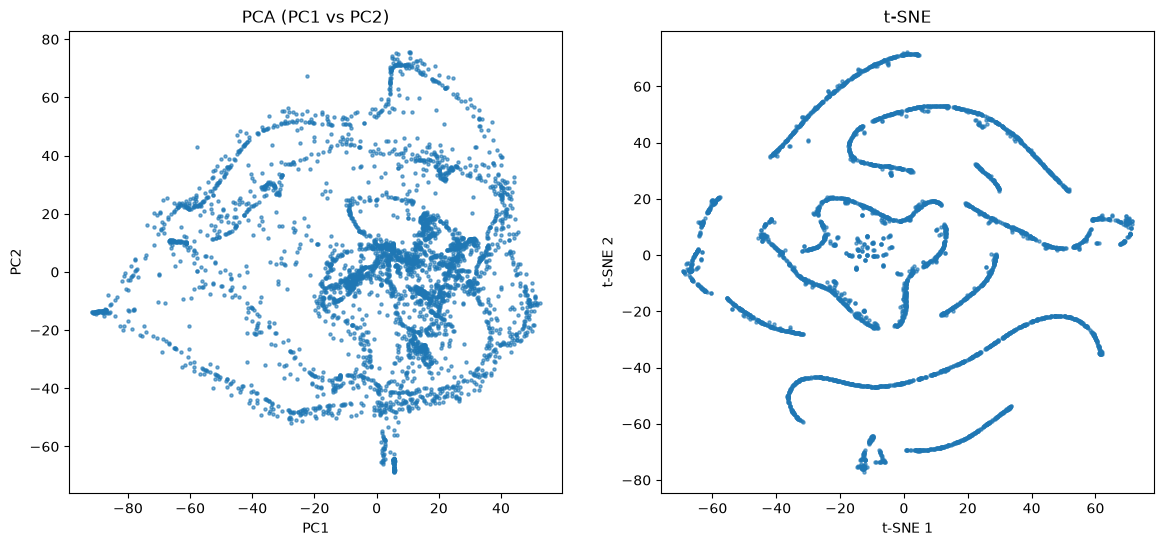

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np


pca = PCA(n_components=200, random_state=42)
X_pca = pca.fit_transform(X_norm)

cum = np.cumsum(pca.explained_variance_ratio_)
plt.plot(cum)
plt.xlabel("Antall komponenter"); plt.ylabel("Kumulativ forklart varians")
plt.grid(alpha=0.3); plt.show()
print("90% varians:", np.searchsorted(cum, 0.90) + 1, "komponenter")


X_tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    random_state=42,
).fit_transform(X_pca[:, :50])


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], s=5, alpha=0.6)
axes[0].set_title("PCA (PC1 vs PC2)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")

axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], s=5, alpha=0.6)
axes[1].set_title("t-SNE")
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2")
plt.show()

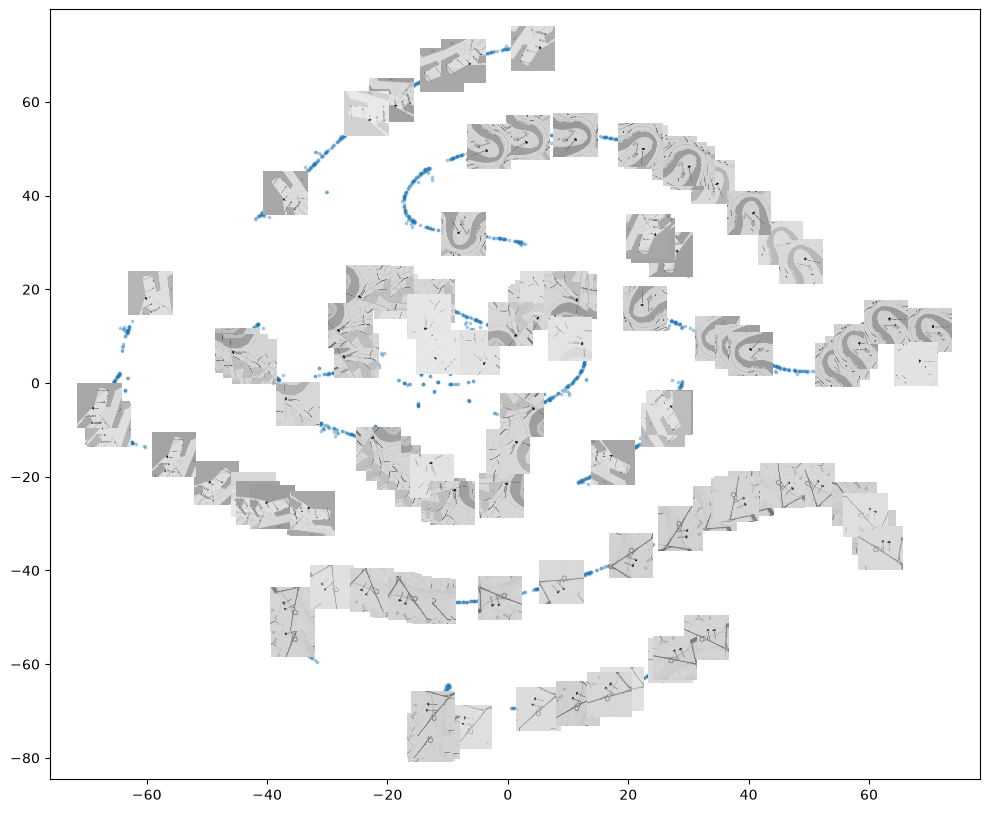

In [103]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

fig, ax = plt.subplots(figsize=(12, 10))
ax.scatter(X_tsne[:, 0], X_tsne[:, 1], s=3, alpha=0.3)

rng = np.random.default_rng(42)
for i in rng.choice(len(imgs), 120, replace=False):
    im = OffsetImage(imgs[i], cmap="gray", zoom=0.25)
    ax.add_artist(AnnotationBbox(im, X_tsne[i], frameon=False))
plt.show()

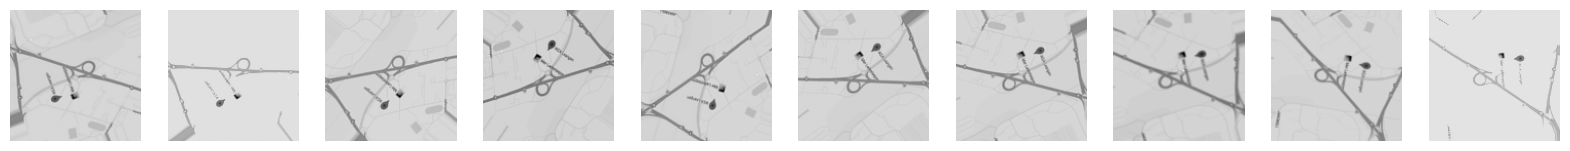

In [105]:
sel = np.where((X_tsne[:, 0] > 0) & (X_tsne[:, 1] < -25))[0]   # juster boksen til en streng
sel = sel[np.argsort(X_tsne[sel, 0])]
pick = sel[np.linspace(0, len(sel)-1, 10).astype(int)]
fig, axes = plt.subplots(1, 10, figsize=(20, 2.2))
for ax, i in zip(axes, pick):
    ax.imshow(imgs[i], cmap="gray"); ax.axis("off")
plt.show()

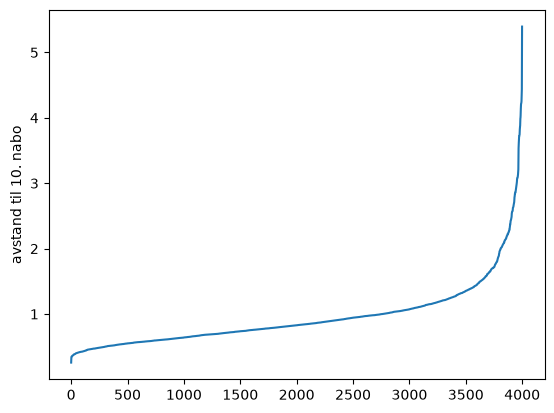

(array([-1,  0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,
       16]), array([ 24, 250, 671, 193, 377, 122,  69, 210, 336, 164, 338, 263,  78,
       116, 413, 118, 178,  80]))


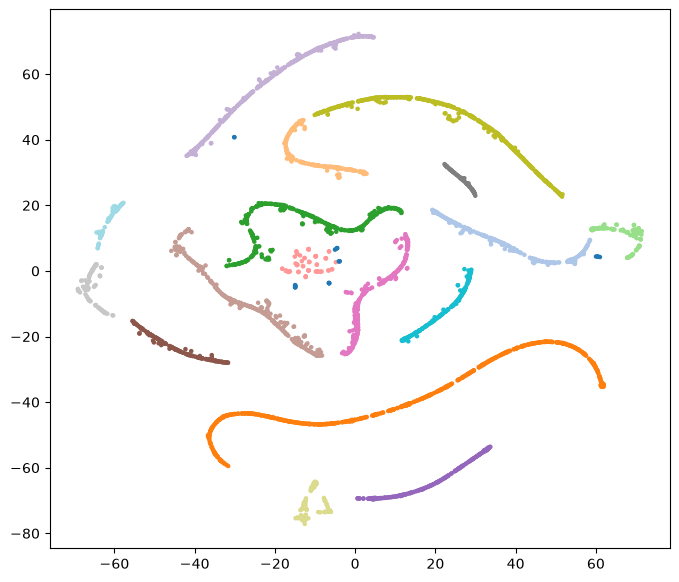

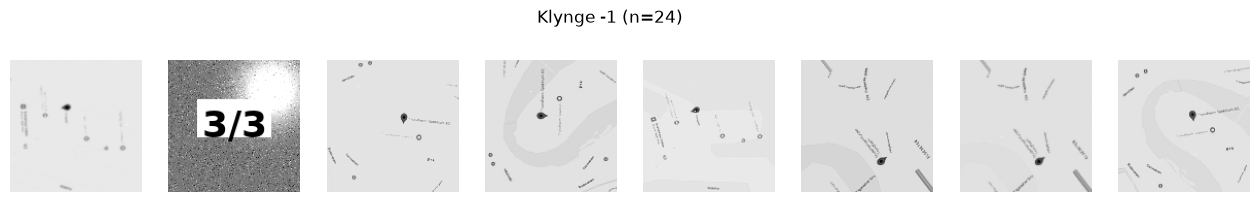

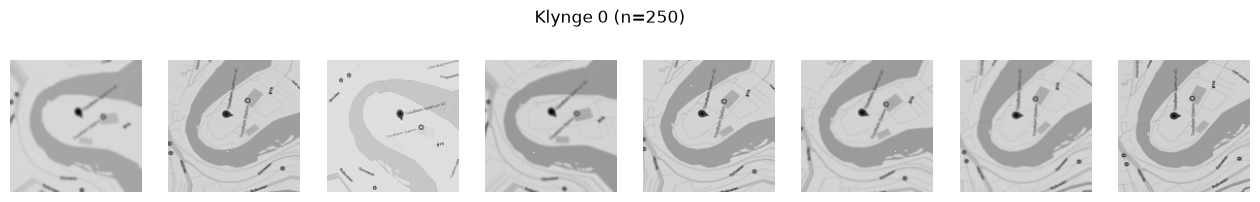

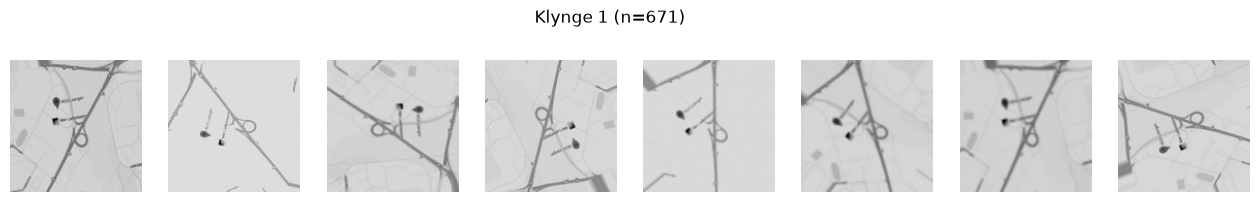

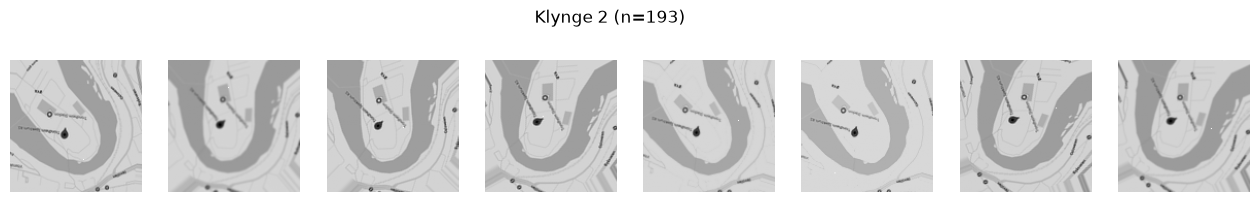

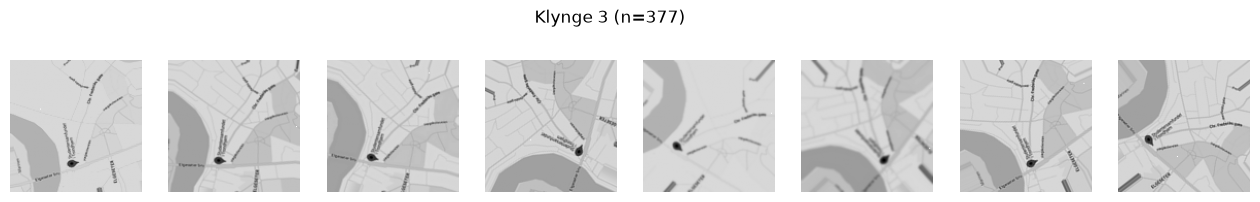

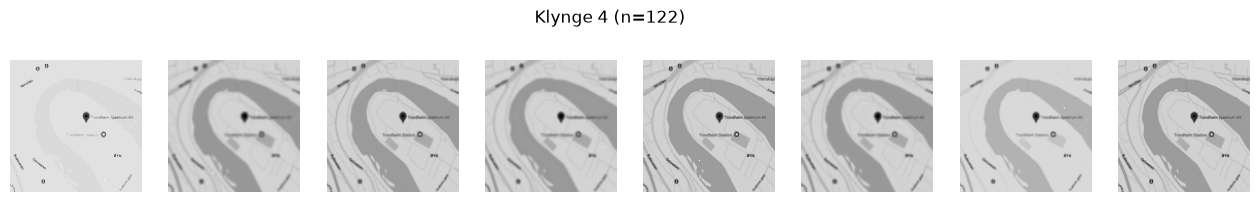

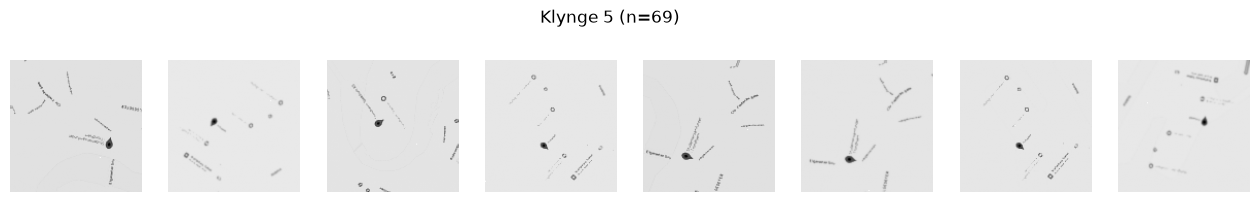

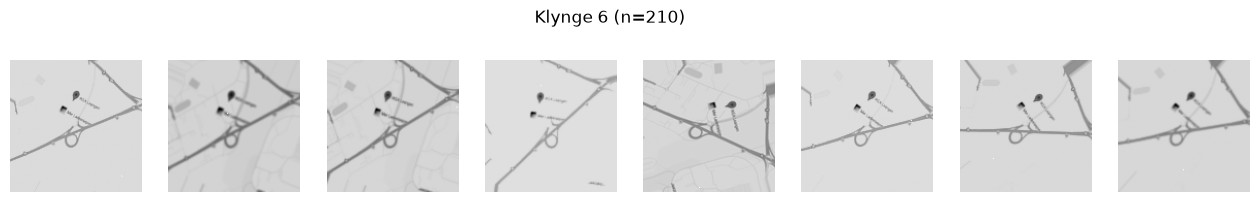

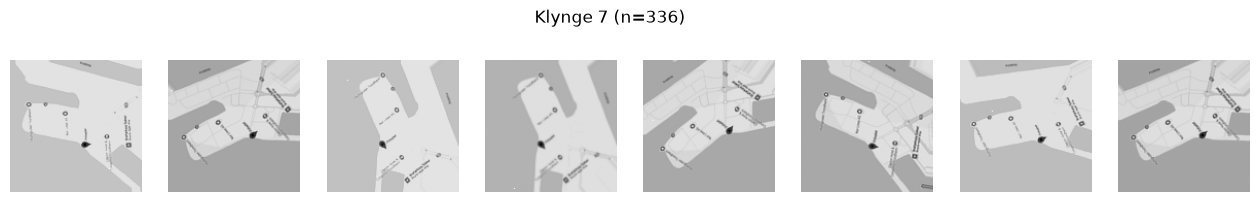

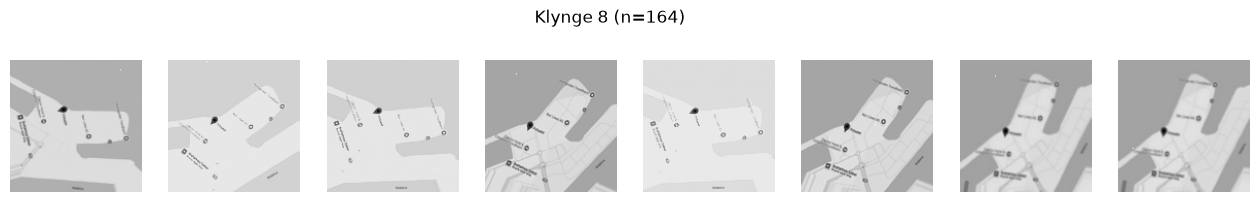

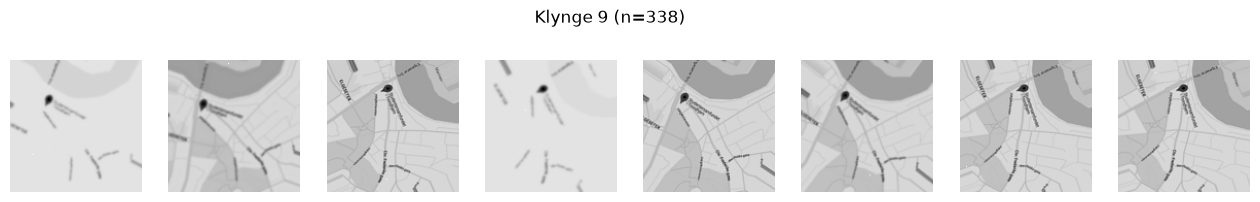

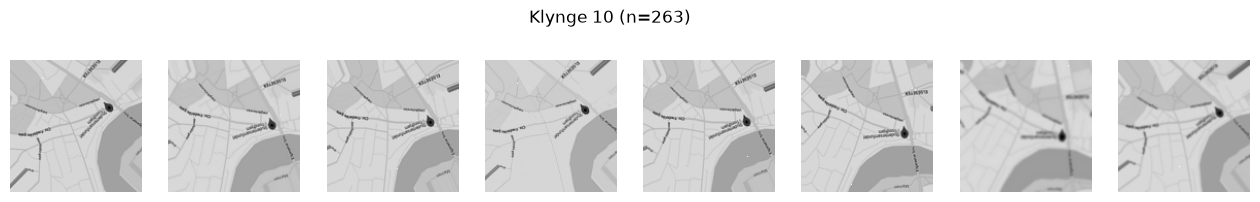

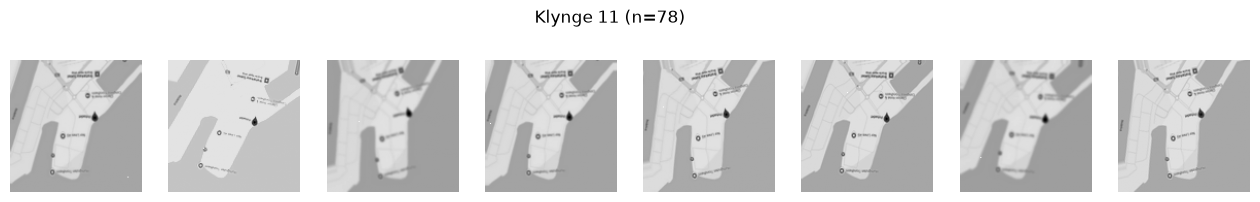

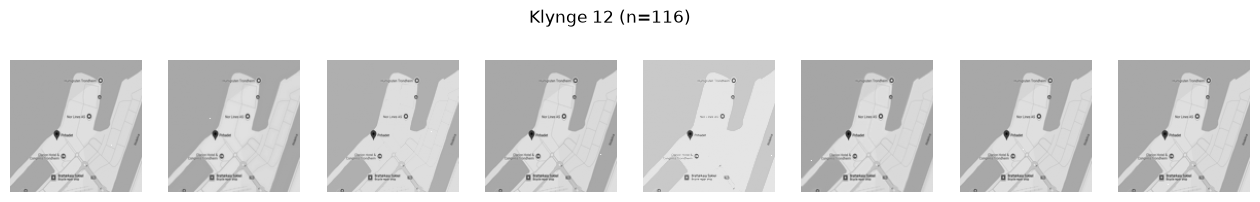

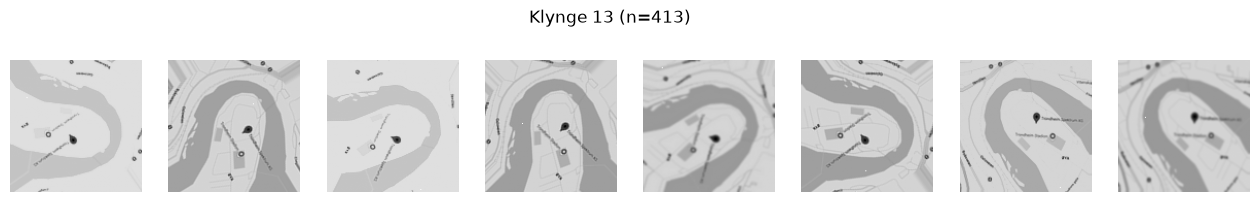

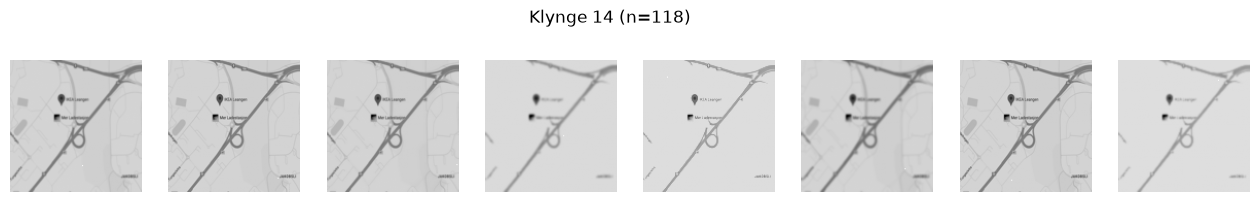

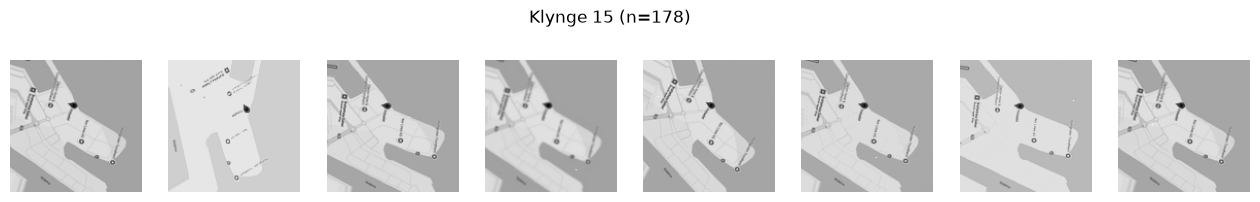

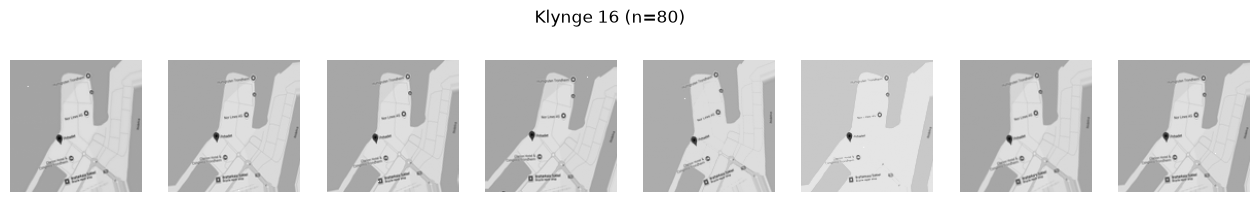

In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# k-distance-plot for å velge eps
d = np.sort(NearestNeighbors(n_neighbors=10).fit(X_tsne).kneighbors(X_tsne)[0][:, -1])
plt.plot(d); plt.ylabel("avstand til 10. nabo"); plt.show()

labels = DBSCAN(eps=3, min_samples=10).fit_predict(X_tsne)   # sett eps fra albuen
print(np.unique(labels, return_counts=True))

plt.figure(figsize=(8, 7))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, cmap="tab20", s=5)
plt.show()

# tilfeldige bilder per klynge, for å se hva hver klynge er
rng = np.random.default_rng(42)
for c in np.unique(labels):
    idx = np.where(labels == c)[0]
    pick = rng.choice(idx, min(8, len(idx)), replace=False)
    fig, axes = plt.subplots(1, len(pick), figsize=(2 * len(pick), 2.4))
    for ax, i in zip(np.atleast_1d(axes), pick):
        ax.imshow(imgs[i], cmap="gray"); ax.axis("off")
    fig.suptitle(f"Klynge {c} (n={len(idx)})")
    plt.show()

In [ ]:
group_map = {
    0: 0, 2: 0, 4: 0, 13: 0,            # elvesving
    1: 1, 6: 1, 14: 1,                  # motorveikryss
    7: 2, 8: 2, 11: 2, 12: 2, 15: 2, 16: 2,   # havn
    3: 3, 9: 3, 10: 3, 5: 2,            # elvebredd (5 er usikker) jeg prøvde å sette den i forskjellige og fant at 2 ga best på kaggle :)
}
merged = np.array([group_map.get(l, -1) for l in labels])

# Støy (-1) til nærmeste kjente punkt
from sklearn.neighbors import KNeighborsClassifier
mask = merged != -1
knn = KNeighborsClassifier(n_neighbors=5).fit(X_pca[mask, :50], merged[mask])
merged[~mask] = knn.predict(X_pca[~mask, :50])

submission = pd.DataFrame({"ID": data["ID"], "cluster": merged.astype(int)})
submission.to_csv("submission.csv", index=False)

Fra og med her fikk jeg en submission som var over 0.9 på kaggle, men jeg ville se hvor bra jeg kunne få den, så nedover prøve jeg masse forskjellige mer avanserte metoder i samarbeid med Claude bare for å utforske litt. Så ki deklarasjon herfra og ut. 

[0.13 0.13 0.2  0.27 0.27 0.27 0.33 0.33 0.33 0.33 0.33 0.4  0.4  0.4
 0.47 0.47 0.47 0.47 0.47 0.47 0.47 0.53 0.53 0.53 0.53 0.53 0.53 0.53
 0.53 0.6 ]


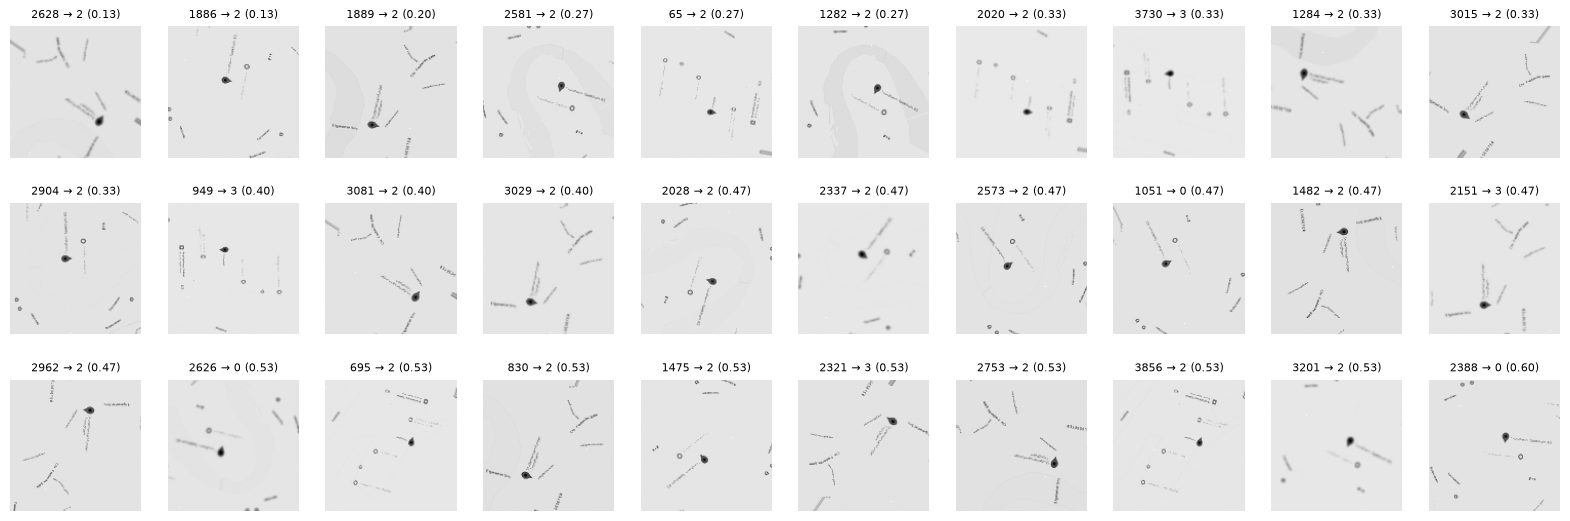

In [117]:
from sklearn.neighbors import NearestNeighbors

Z = X_pca[:, :50]
nbrs = NearestNeighbors(n_neighbors=16).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
agree = (merged[nbrs] == merged[:, None]).mean(axis=1)   # andel naboer med samme label

low = np.argsort(agree)[:30]
print(agree[low].round(2))

fig, axes = plt.subplots(3, 10, figsize=(20, 6.5))
for ax, i in zip(axes.ravel(), low):
    ax.imshow(imgs[i], cmap="gray"); ax.axis("off")
    ax.set_title(f"{i} → {merged[i]} ({agree[i]:.2f})", fontsize=8)
plt.show()

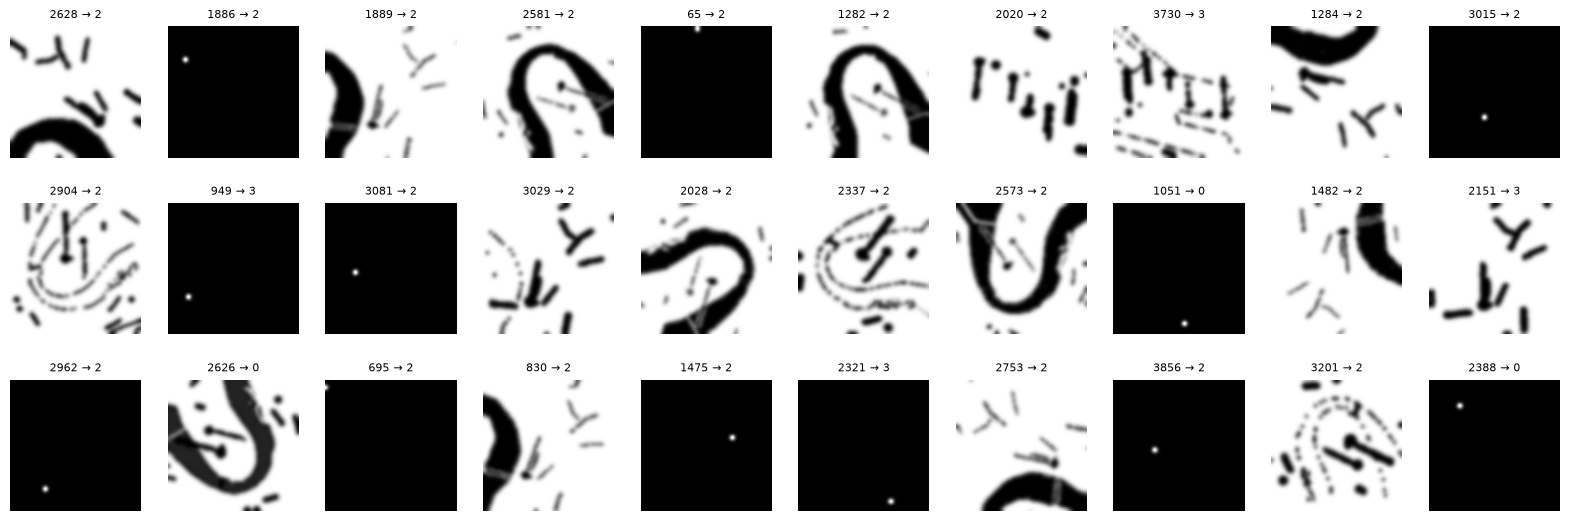

In [118]:
from scipy.ndimage import gaussian_filter

def enhance(im):
    lo, hi = np.percentile(im, [10, 99.5])           # markør/tekst ligger under 10-persentilen
    out = np.clip((im - lo) / (hi - lo + 1e-8), 0, 1)
    return gaussian_filter(out, 2)

fig, axes = plt.subplots(3, 10, figsize=(20, 6.5))
for ax, i in zip(axes.ravel(), low):
    ax.imshow(enhance(imgs[i]), cmap="gray"); ax.axis("off")
    ax.set_title(f"{i} → {merged[i]}", fontsize=8)
plt.show()

In [119]:
lowdetail = np.where(np.isin(labels, [5, -1]) | (agree < 0.7))[0]   # juster terskelen
E = np.stack([enhance(imgs[i])[::4, ::4].ravel() for i in range(len(imgs))])  # 32x32

knn = KNeighborsClassifier(n_neighbors=7).fit(E[~np.isin(np.arange(len(E)), lowdetail)],
                                              merged[~np.isin(np.arange(len(E)), lowdetail)])
pred = knn.predict(E[lowdetail])
print((pred != merged[lowdetail]).sum(), "av", len(lowdetail), "endrer label")

79 av 102 endrer label


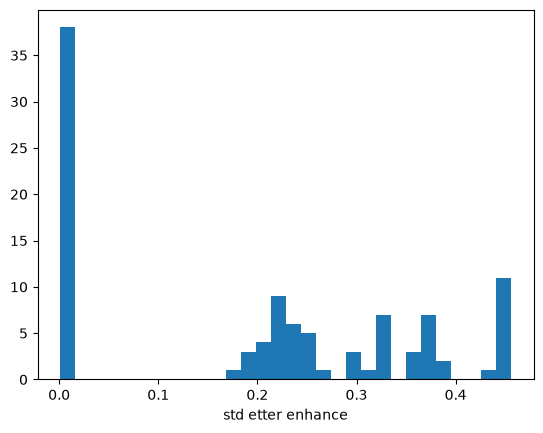

In [120]:
# 1. Tren kNN på de trygge bildene
train_mask = np.ones(len(E), bool)
train_mask[lowdetail] = False
knn = KNeighborsClassifier(n_neighbors=7).fit(E[train_mask], merged[train_mask])

# 2. Sikkerhet og hvor mye struktur hvert lavdetalj-bilde har
proba = knn.predict_proba(E[lowdetail])
pred = knn.classes_[proba.argmax(1)]
conf = proba.max(1)
info = np.array([enhance(imgs[i]).std() for i in lowdetail])

plt.hist(info, bins=30); plt.xlabel("std etter enhance"); plt.show()   # velg terskel her



In [121]:
thr = 0.1   # juster etter histogrammet
sel = (conf >= 0.7) & (info > thr)
print(sel.sum(), "av", len(lowdetail), "overskrives;",
      (pred[sel] != merged[lowdetail][sel]).sum(), "endrer label")

merged2 = merged.copy()
merged2[lowdetail[sel]] = pred[sel]

submission2 = pd.DataFrame({"ID": data["ID"], "cluster": merged2.astype(int)})
submission2.to_csv("submission_v2.csv", index=False)

58 av 102 overskrives; 35 endrer label


The following is just something i pulled from claude where I asked it to otry a bunch of different stuff to see how good i could get the accuracy. I got it above .99 without all this stuff. 

Validering: kNN uten rotasjon 1.000 | med rotasjons-augmentering 1.000
64 usikre bilder med bakgrunn, 61 sikre nok, 33 endret label
38 flate bilder beholder label fra PCA/DBSCAN (ingen bakgrunn å gå på)
0 anomalikandidater (naboavstand > median + 8·MAD); 0 av dem er DBSCAN-støy


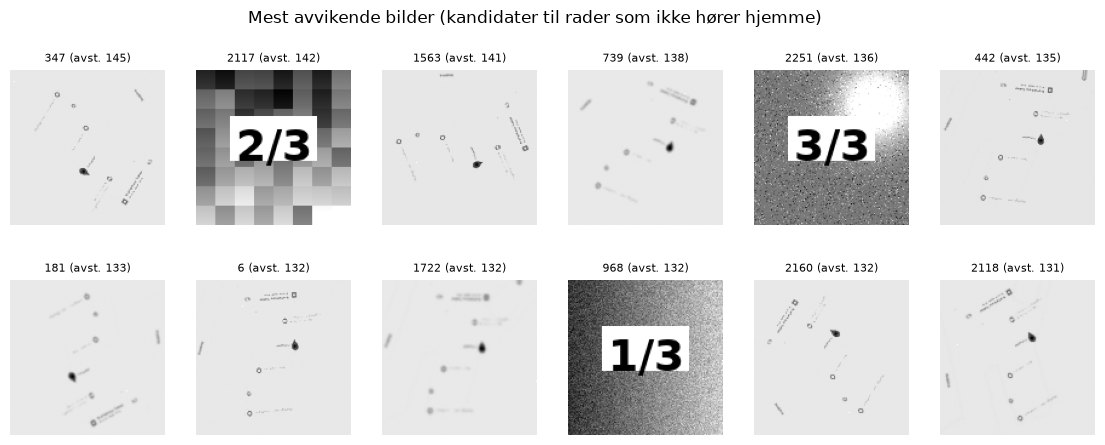

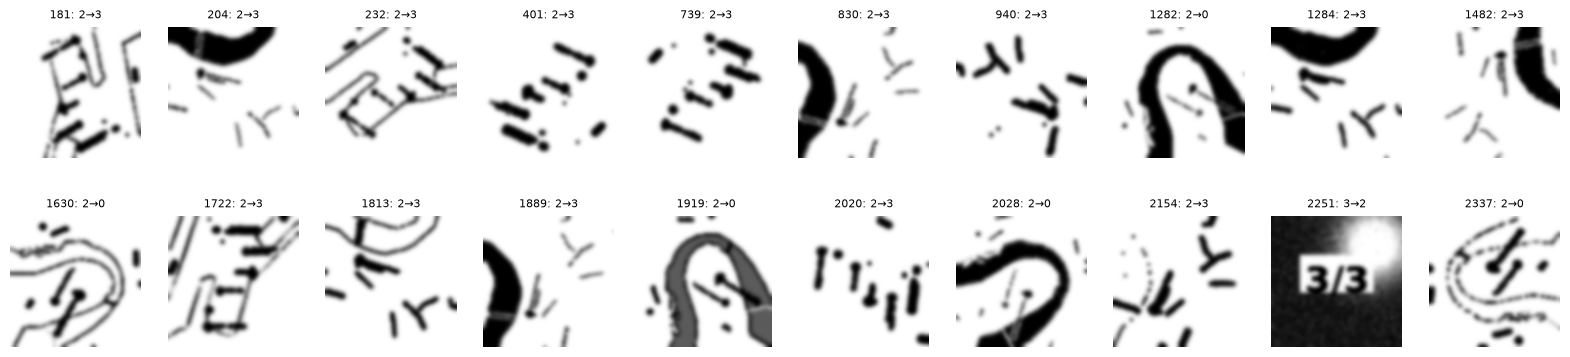

cluster
0     994
1     999
2    1001
3    1006
Name: count, dtype: int64


In [ ]:

import os, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, rotate
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors


THR_INFO            = 0.10   
MIN_CONF            = 0.70   
MIN_VAL_ACC         = 0.95   
ANGLES              = range(0, 360, 30)  
ANOMALY_OWN_CLUSTER = False 


expected = [24, 250, 671, 193, 377, 122, 69, 210, 336, 164, 338, 263, 78, 116, 413, 118, 178, 80]
counts = np.unique(labels, return_counts=True)[1].tolist()
if counts != expected:
    print("ADVARSEL: `labels` er ikke de samme som da group_map ble laget. Kjør DBSCAN-cellen på nytt "
          "(uten å kjøre t-SNE på nytt) og sjekk klyngene før du bruker kartleggingen.")

group_map = {
    0: 0, 2: 0, 4: 0, 13: 0,                  
    1: 1, 6: 1, 14: 1,                        
    7: 2, 8: 2, 11: 2, 12: 2, 15: 2, 16: 2,     
    3: 3, 9: 3, 10: 3, 5: 2,                  
}
base = np.array([group_map.get(l, -1) for l in labels])


Z = X_pca[:, :50]
known = base != -1
base[~known] = KNeighborsClassifier(n_neighbors=5).fit(Z[known], base[known]).predict(Z[~known])


nbrs = NearestNeighbors(n_neighbors=16).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
agree = (base[nbrs] == base[:, None]).mean(axis=1)          
lowdetail = np.isin(labels, [5, -1]) | (agree < 0.7)


def enhance(im):
    lo, hi = np.percentile(im, [10, 99.5])                
    return gaussian_filter(np.clip((im - lo) / (hi - lo + 1e-8), 0, 1), 2)

F = np.empty((len(imgs), 32, 32), dtype=np.float32)
info = np.empty(len(imgs))
for i, im in enumerate(imgs):
    e = enhance(im)
    F[i] = e[::4, ::4]
    info[i] = e.std()                                       

def prep(A):                                          
    V = A.reshape(len(A), -1)
    return (V - V.mean(1, keepdims=True)) / (V.std(1, keepdims=True) + 1e-8)

def rot_aug(A, y, angles):                                  
    Xs, ys = [], []
    for a in angles:
        R = A if a == 0 else np.stack([rotate(f, a, reshape=False, order=1, mode="nearest") for f in A])
        Xs.append(prep(R)); ys.append(y)
    return np.vstack(Xs), np.concatenate(ys)


safe = ~lowdetail & (info > THR_INFO)
cand = np.where(safe)[0]
val = cand[np.argsort(info[cand])[:300]]                    
trn = np.setdiff1d(cand, val)

acc_plain = (KNeighborsClassifier(7).fit(prep(F[trn]), base[trn]).predict(prep(F[val])) == base[val]).mean()
Xtr, ytr = rot_aug(F[trn], base[trn], ANGLES)
val_acc = (KNeighborsClassifier(15).fit(Xtr, ytr).predict(prep(F[val])) == base[val]).mean()
print(f"Validering: kNN uten rotasjon {acc_plain:.3f} | med rotasjons-augmentering {val_acc:.3f}")


final = base.copy()
tgt = np.where(lowdetail & (info > THR_INFO))[0]
if val_acc >= MIN_VAL_ACC and len(tgt):
    Xtr, ytr = rot_aug(F[cand], base[cand], ANGLES)
    clf = KNeighborsClassifier(15).fit(Xtr, ytr)
    proba = clf.predict_proba(prep(F[tgt]))
    pred, conf = clf.classes_[proba.argmax(1)], proba.max(1)
    use = conf >= MIN_CONF
    final[tgt[use]] = pred[use]
    print(f"{len(tgt)} usikre bilder med bakgrunn, {use.sum()} sikre nok, "
          f"{(final != base).sum()} endret label")
else:
    print("Validering for lav (eller ingen kandidater): beholder base-labels.")
print(f"{(lowdetail & (info <= THR_INFO)).sum()} flate bilder beholder label fra PCA/DBSCAN (ingen bakgrunn å gå på)")


Xn = X_norm.astype(np.float32)
dist = NearestNeighbors(n_neighbors=6).fit(Xn).kneighbors(Xn)[0][:, 1:].mean(1)
med = np.median(dist); mad = np.median(np.abs(dist - med)) * 1.4826
anom = np.where(dist > med + 8 * mad)[0]
print(f"{len(anom)} anomalikandidater (naboavstand > median + 8·MAD); {(labels[anom] == -1).sum()} av dem er DBSCAN-støy")
if ANOMALY_OWN_CLUSTER and len(anom):
    final[anom] = final.max() + 1

top = np.argsort(dist)[::-1][:12]
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(axes.ravel(), top):
    ax.imshow(imgs[i], cmap="gray"); ax.axis("off"); ax.set_title(f"{i} (avst. {dist[i]:.0f})", fontsize=8)
plt.suptitle("Mest avvikende bilder (kandidater til rader som ikke hører hjemme)"); plt.show()


chg = np.where(final != base)[0][:20]
if len(chg):
    fig, axes = plt.subplots(2, 10, figsize=(20, 4.5))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), chg):
        ax.imshow(enhance(imgs[i]), cmap="gray"); ax.set_title(f"{i}: {base[i]}→{final[i]}", fontsize=8)
    plt.show()


sub = pd.DataFrame({"ID": data["ID"], "cluster": final.astype(int)})
sample = pd.read_csv("sample_submission.csv")
assert len(sub) == len(sample) and (sub["ID"].values == sample["ID"].values).all()
if os.path.exists("submission.csv") and not os.path.exists("submission_prev.csv"):
    shutil.copy("submission.csv", "submission_prev.csv")   
sub.to_csv("submission.csv", index=False)
print(sub["cluster"].value_counts().sort_index())

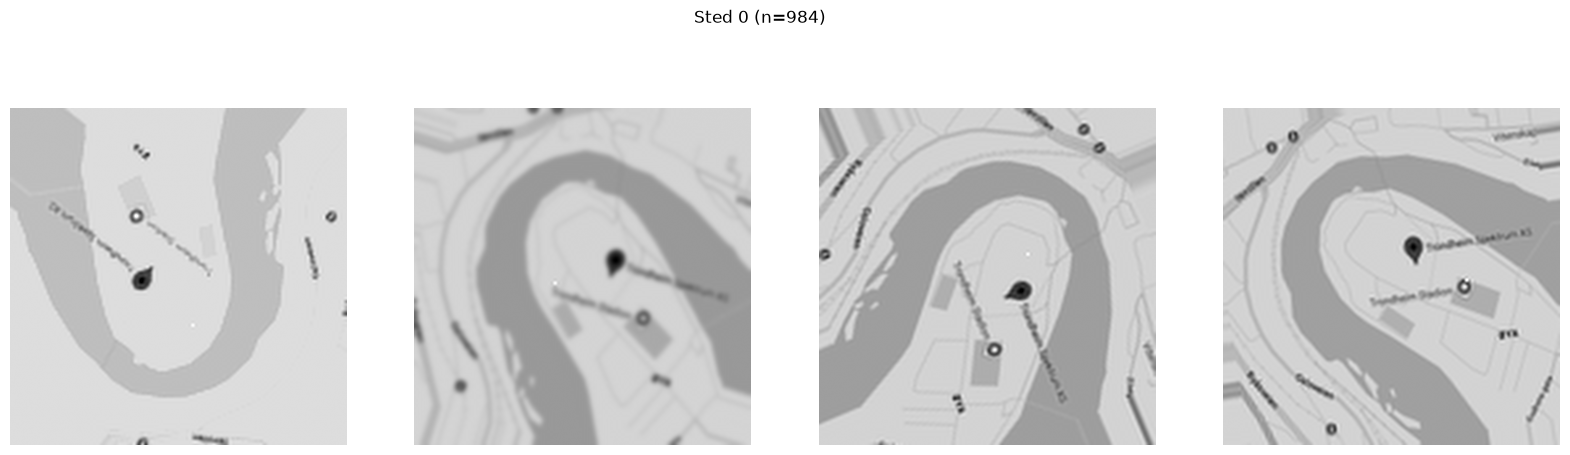

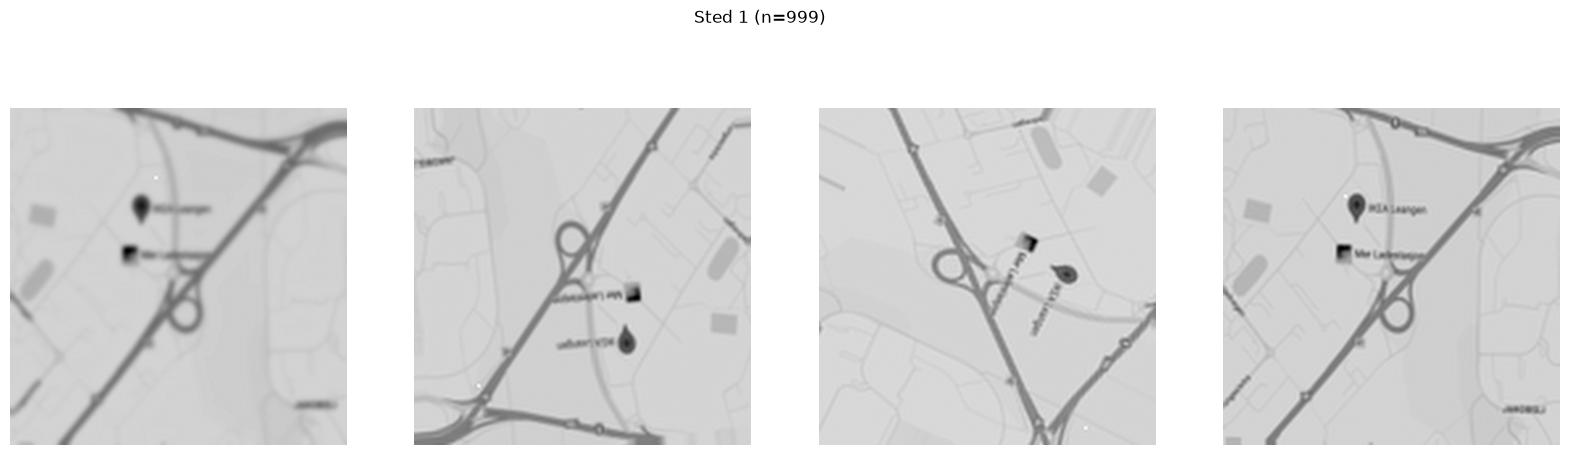

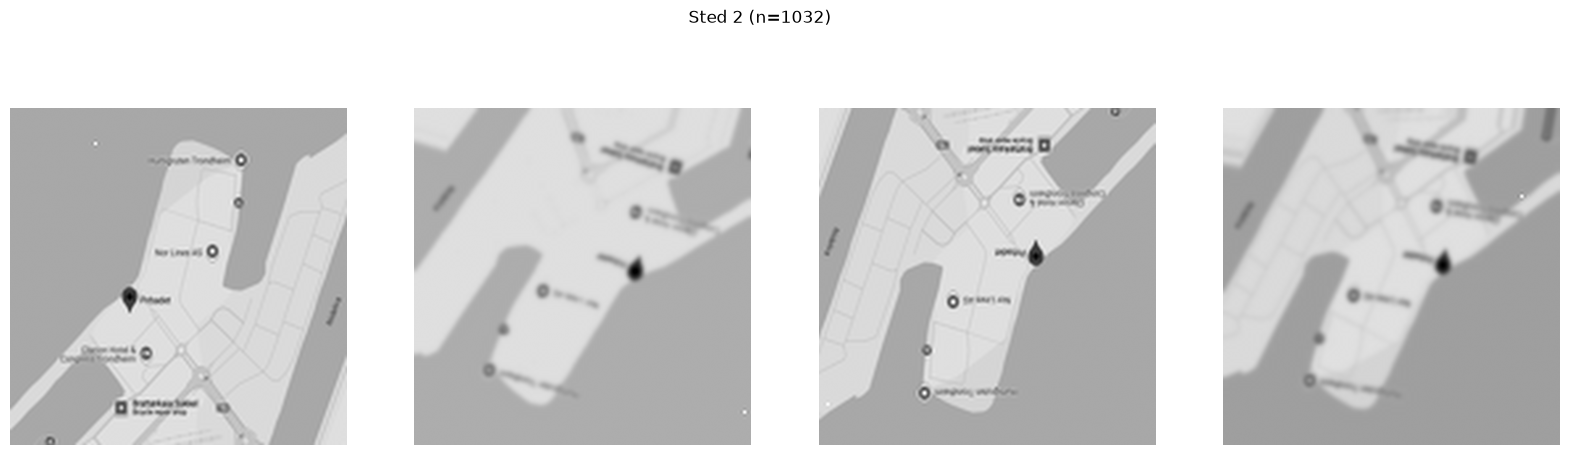

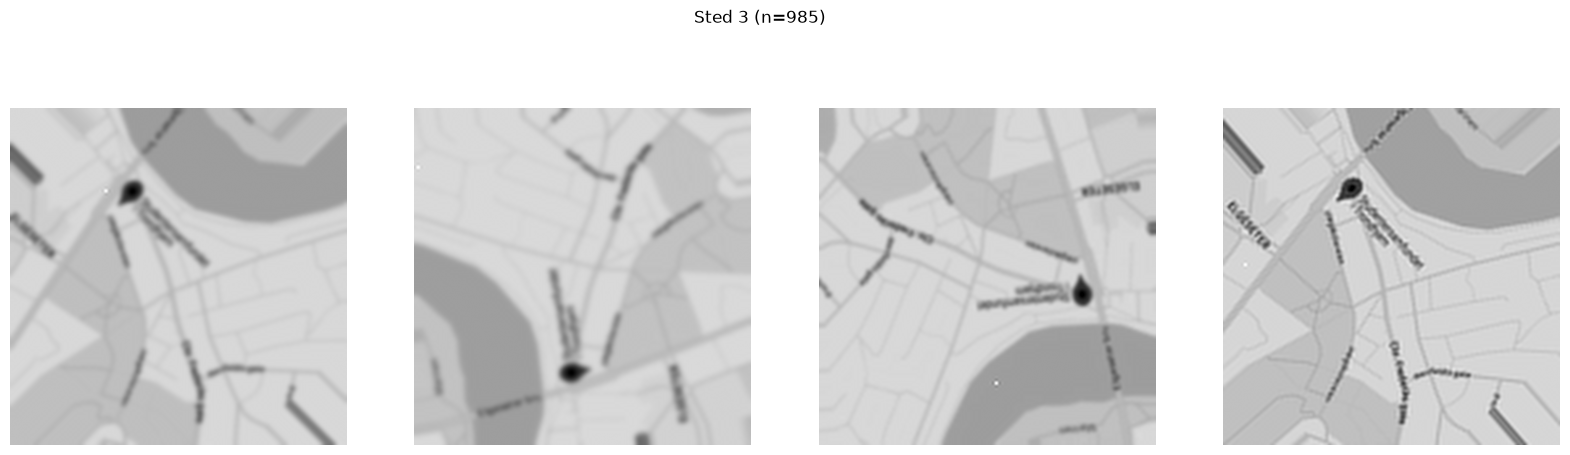

In [128]:
for g in range(4):
    members = np.where(base == g)[0]
    idx = np.random.default_rng(42).choice(members, 4, replace=False)    # høyest info i gruppen, ingen terskel
    fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))
    for ax, i in zip(axes, idx):
        ax.imshow(imgs[i], cmap="gray", interpolation="lanczos"); ax.axis("off")
    fig.suptitle(f"Sted {g} (n={len(members)})"); plt.show()

### ❓ Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.
PCA alone was not very helpful. The cumulative explained variance rose slowly, so there is no simple low dimensional linear structure, and PC1 vs PC2 was just messy blob with no clear groups. t-SNE (running on 50 PC and perplexity 30) revealed the structure. About 17 curved strands with some spread out dots here and there. This gave a first estimate of k, but plotting the actual images along the strands showed several strands were the same location just rotated and zoomed in/out. You could actually merge this to 4 locations. PCA preserves the global variance, but it mixed the groups while t-SNE seperates local neighbourhoods well but distorts distances, so its strand count overestimates the true number of clusters.   

### ❓ Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.
I ran dbscan on the 2d tsne embeddin, which gave 17 clusters plus 24 noise points. I inspected sample images from each cluster and merges trands showing the same location into 4 groups. Noise points were assigned with a k nearest neighbour classifier (k=5) in PCA space. Finally, unvertain images (those whose neighbours disagreed with their label) were re-labelled with a kNN on contrast stretched 32x32 background features, with rotation augmentation, only when validation accuracy on trusted images was high enough. dbscar fits this data better than kmeans. it doesnt need k in advance and follows strands in tsne, whereas kmeans assumes compact roughly spherical clusters, and would cut the strands into pieces or merge neighbouring ones.

### ❓ What is the hidden modality? How does this impact dimensionality reduction and clustering?
The hidden modality is images. Each row is a flattened 128x128 grayscale map tile of Trondheim, with the columns shuffled. The header row contained the real pixel positions (col_N), and sorting the columns by N restored the images. Treating the data as imagens means raw pixel vectors are very high-dimensional, and euclidian distance between them is a poor similarity measure. The same location rotated, shifted, zoomed with different brightness gives a completely different pixel vector. This is why PCA needed many components, and why tsne produced strands instead of compact "blobs".

### ❓ List the facilities in Trondheim and how you identified them.
Taking the pictures at face value, the one that looks like a harbor is definitively Pirbadet, and the one with the river is Trondheim stadion. I think the highway one is IKEA leangen and the one with a bridge must be Elgseterbroa by Studentersamfundet. I identified these by using my knowledge of the city. 

### ❓ How did you detect the rows that do not belong, and what were they?
I used two signals. dbscan noise points (label -1, 24 points) and the average distance from each image to its nearest neghbours in normalised pixel space. Images that are unusually far from everything else are candidates. Plotting the most deviating images showed some images that werent evnen maps, like the ones with huge texts "x/3" on them. 

---

## Note: Clustering accuracy metric

Kaggle scores clustering with **label-invariant** accuracy: only the grouping matters, not the numeric ids.

If true labels are `[0, 0, 0, 1, 1, 1]` and you predict `[1, 1, 1, 0, 0, 0]`, accuracy is **1.0** because clusters match after renaming.

### How it is computed

1. Build a contingency matrix between true and predicted labels.
2. Find the best label matching (Hungarian algorithm / `linear_sum_assignment`).
3. Accuracy = matched points / total points.

---

In [14]:
import scipy.optimize
import sklearn.metrics


def calculate_clustering_accuracy(true_labels: np.ndarray, cluster_labels: np.ndarray) -> float:
    """Clustering accuracy with optimal permutation of cluster ids."""
    if true_labels.size != cluster_labels.size:
        raise ValueError("true_labels and cluster_labels must have the same length.")

    contingency = sklearn.metrics.cluster.contingency_matrix(true_labels, cluster_labels)
    row_ind, col_ind = scipy.optimize.linear_sum_assignment(-contingency)
    correct = contingency[row_ind, col_ind].sum()
    return correct / true_labels.size

In [15]:
true_labels = np.array([0, 1, 2, 0, 1, 2])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(1.0)

In [16]:
# Single cluster in ground truth: accuracy is share of majority predicted cluster
true_labels = np.array([0, 0, 0, 0, 0, 0])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.3333333333333333)

In [17]:
# Wrong number of groups: low accuracy
true_labels = np.array([1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 0, 0, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.5)